In [ ]:
# =============================================================================
# ESPCN x4 Super-Resolution on Sentinel-2 — Thanjavur (Tanjore) paddy belt, TN
# Single-figure output: 1 row × 2 cols (LR | ESPCN x4)
# =============================================================================

import subprocess, sys
for pkg in ["pystac-client", "rasterio", "torch", "matplotlib",
            "numpy", "Pillow", "scikit-image"]:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

import numpy as np
import torch
import torch.nn as nn
import torch.nn.init as init
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import Window
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
from pystac_client import Client
import sys, types

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

# =============================================================================
# 0. ESPCN architecture + pretrained weights
# =============================================================================
class Net(nn.Module):
    def __init__(self, upscale_factor=4):
        super().__init__()
        self.mode = "tanh"
        self.conv1 = nn.Conv2d(1, 64, (5, 5), (1, 1), (2, 2))
        self.conv3 = nn.Conv2d(64, 32, (3, 3), (1, 1), (1, 1))
        self.conv4 = nn.Conv2d(32, upscale_factor ** 2, (3, 3), (1, 1), (1, 1))
        self.pixel_shuffle = nn.PixelShuffle(upscale_factor)
        self._initialize_weights()

    def _initialize_weights(self):
        init.orthogonal_(self.conv1.weight, init.calculate_gain(self.mode))
        init.orthogonal_(self.conv3.weight, init.calculate_gain(self.mode))
        init.orthogonal_(self.conv4.weight)

    def forward(self, x):
        x = torch.tanh(self.conv1(x))
        x = torch.tanh(self.conv3(x))
        return torch.sigmoid(self.pixel_shuffle(self.conv4(x)))

model_shim = types.ModuleType("model")
model_shim.Net = Net
sys.modules["model"] = model_shim

WEIGHTS_URL = (
    "https://github.com/JacquesOlivierLachaud/SuperRes-ESPCN/"
    "raw/main/models/model-x4-coco-l3-stanh.pth"
)
loaded = torch.hub.load_state_dict_from_url(
    WEIGHTS_URL, map_location=DEVICE, progress=True, weights_only=False
)
if isinstance(loaded, nn.Module):
    espcn = loaded.to(DEVICE).eval()
else:
    espcn = Net(upscale_factor=4).to(DEVICE)
    espcn.load_state_dict(loaded)
    espcn.eval()
print("✅ ESPCN x4 loaded.")

# =============================================================================
# 1. Area of interest — Cauvery Delta paddy belt, Thanjavur, Tamil Nadu
# =============================================================================
LON, LAT = 79.160, 10.810                      # Thanjavur paddy fields, TN
HALF = 0.03                                    # ~3 km half-width → ~6 km box
BBOX = [LON - HALF, LAT - HALF, LON + HALF, LAT + HALF]
TIME_WINDOW = "2023-01-01/2024-04-30"          # spans rabi + summer, clear skies
LABEL = f"Thanjavur paddy belt, Tamil Nadu  ({LAT:.3f}, {LON:.3f})"

CROP = 256
SCALE = 4
TARGET = CROP * SCALE

# =============================================================================
# 2. Fetch Sentinel-2 L2A RGB crop
# =============================================================================
catalog = Client.open("https://earth-search.aws.element84.com/v1")
search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=BBOX,
    datetime=TIME_WINDOW,
    query={"eo:cloud_cover": {"lt": 10}},
    max_items=5,
)
items = list(search.items())
assert items, "No scenes found — widen TIME_WINDOW or bump cloud threshold."
item = items[0]
print(f"Scene: {item.id}  ({item.datetime.date()}, "
      f"{item.properties.get('eo:cloud_cover'):.2f}% cloud)")

def read_window(url, size=CROP):
    with rasterio.open(url) as src:
        h, w = src.height, src.width
        y0, x0 = h // 2 - size // 2, w // 2 - size // 2
        return src.read(1, window=Window(x0, y0, size, size))

red   = read_window(item.assets["red"].href)
green = read_window(item.assets["green"].href)
blue  = read_window(item.assets["blue"].href)

def percentile_stretch(rgb, p_low=2, p_high=98):
    out = np.zeros_like(rgb, dtype=np.uint8)
    for c in range(3):
        lo, hi = np.percentile(rgb[..., c], [p_low, p_high])
        if hi <= lo:
            hi = lo + 1e-6
        out[..., c] = (np.clip((rgb[..., c] - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)
    return out

lr_crop = percentile_stretch(np.stack([red, green, blue], -1).astype(np.float32))
print(f"LR crop: {lr_crop.shape}")

# =============================================================================
# 3. ESPCN x4 on the Y channel
# =============================================================================
lr_pil = Image.fromarray(lr_crop)
y_ch, cb_ch, cr_ch = lr_pil.convert("YCbCr").split()

y_np = np.asarray(y_ch).astype(np.float32) / 255.0
y_t = torch.from_numpy(y_np).unsqueeze(0).unsqueeze(0).to(DEVICE)
with torch.no_grad():
    sr_y = espcn(y_t).squeeze().cpu().numpy()
sr_y_np = (sr_y * 255).clip(0, 255).astype(np.uint8)

cb_up = cb_ch.resize((TARGET, TARGET), Image.BICUBIC)
cr_up = cr_ch.resize((TARGET, TARGET), Image.BICUBIC)
sr_np = np.array(
    Image.merge("YCbCr", [Image.fromarray(sr_y_np), cb_up, cr_up]).convert("RGB")
)

# Bicubic baseline for PSNR/SSIM reference
bicubic = np.array(lr_pil.resize((TARGET, TARGET), Image.BICUBIC))
p = psnr(bicubic.astype(np.float32)/255, sr_np.astype(np.float32)/255, data_range=1.0)
s = ssim(bicubic.astype(np.float32)/255, sr_np.astype(np.float32)/255,
         channel_axis=2, data_range=1.0)
print(f"PSNR(bicubic vs ESPCN) = {p:.2f} dB | SSIM = {s:.3f}")

# =============================================================================
# 4. Single-figure side-by-side visualisation
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(lr_crop)
axes[0].set_title(f"LR input  ({CROP}×{CROP}, 10 m)", fontsize=12, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(sr_np)
axes[1].set_title(
    f"ESPCN x4  ({TARGET}×{TARGET}, 2.5 m)  —  "
    f"PSNR {p:.2f} dB / SSIM {s:.3f}",
    fontsize=12, fontweight="bold",
)
axes[1].axis("off")

fig.suptitle(LABEL + "  —  Sentinel-2 L2A → ESPCN x4",
             fontsize=14, fontweight="bold", y=1.00)
plt.tight_layout()
plt.savefig("espcn_sr_thanjavur.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nSaved figure → espcn_sr_thanjavur.png")

In [ ]:
# =============================================================================
# ESPCN x4 SR on Sentinel-2 — Two Indian Areas (Punjab farmland + Ahmedabad stadium)
# Single-figure output: 2 rows (one per area) × 2 cols (LR | ESPCN x4)
# =============================================================================

import subprocess, sys
for pkg in ["pystac-client", "rasterio", "torch", "matplotlib",
            "numpy", "Pillow", "scikit-image"]:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

import numpy as np
import torch
import torch.nn as nn
import torch.nn.init as init
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import Window
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
from pystac_client import Client
import sys, types

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

# =============================================================================
# 0. ESPCN architecture + weights (load once, reuse for both areas)
# =============================================================================
class Net(nn.Module):
    def __init__(self, upscale_factor=4):
        super().__init__()
        self.mode = "tanh"
        self.conv1 = nn.Conv2d(1, 64, (5, 5), (1, 1), (2, 2))
        self.conv3 = nn.Conv2d(64, 32, (3, 3), (1, 1), (1, 1))
        self.conv4 = nn.Conv2d(32, upscale_factor ** 2, (3, 3), (1, 1), (1, 1))
        self.pixel_shuffle = nn.PixelShuffle(upscale_factor)
        self._initialize_weights()

    def _initialize_weights(self):
        init.orthogonal_(self.conv1.weight, init.calculate_gain(self.mode))
        init.orthogonal_(self.conv3.weight, init.calculate_gain(self.mode))
        init.orthogonal_(self.conv4.weight)

    def forward(self, x):
        x = torch.tanh(self.conv1(x))
        x = torch.tanh(self.conv3(x))
        return torch.sigmoid(self.pixel_shuffle(self.conv4(x)))

model_shim = types.ModuleType("model")
model_shim.Net = Net
sys.modules["model"] = model_shim

WEIGHTS_URL = (
    "https://github.com/JacquesOlivierLachaud/SuperRes-ESPCN/"
    "raw/main/models/model-x4-coco-l3-stanh.pth"
)
loaded = torch.hub.load_state_dict_from_url(
    WEIGHTS_URL, map_location=DEVICE, progress=True, weights_only=False
)
if isinstance(loaded, nn.Module):
    espcn = loaded.to(DEVICE).eval()
else:
    espcn = Net(upscale_factor=4).to(DEVICE)
    espcn.load_state_dict(loaded)
    espcn.eval()
print("✅ ESPCN x4 loaded.")

# =============================================================================
# 1. Two areas of interest in India
# =============================================================================
CROP = 256                # 256 → 1024 after 4x
SCALE = 4
TARGET = CROP * SCALE

# Each entry: (label, bbox [minLon, minLat, maxLon, maxLat], time_window)
AOIS = [
    (
        "Punjab farmland (crop patterns)",
        [75.740, 30.858, 75.775, 30.888],   # ~3 km around Ludhiana–Jalandhar belt
        "2023-02-01/2023-04-30",             # rabi season, fields clearly visible
    ),
    (
        "Narendra Modi Stadium, Ahmedabad (building)",
        [72.585, 23.078, 72.612, 23.104],   # ~2.8 km around the stadium
        "2023-01-01/2023-05-31",
    ),
]

# =============================================================================
# 2. Helpers
# =============================================================================
def percentile_stretch(rgb, p_low=2, p_high=98):
    out = np.zeros_like(rgb, dtype=np.uint8)
    for c in range(3):
        lo, hi = np.percentile(rgb[..., c], [p_low, p_high])
        if hi <= lo:
            hi = lo + 1e-6
        out[..., c] = (np.clip((rgb[..., c] - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)
    return out

def read_window(url, size=CROP):
    with rasterio.open(url) as src:
        h, w = src.height, src.width
        y0, x0 = h // 2 - size // 2, w // 2 - size // 2
        return src.read(1, window=Window(x0, y0, size, size))

def fetch_lr_rgb(bbox, time_window):
    """Search STAC, download a 256x256 RGB crop, return uint8 HWC."""
    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox,
        datetime=time_window,
        query={"eo:cloud_cover": {"lt": 10}},
        max_items=5,
    )
    items = list(search.items())
    assert items, f"No scenes found for bbox={bbox} in {time_window}"
    item = items[0]

    red   = read_window(item.assets["red"].href)
    green = read_window(item.assets["green"].href)
    blue  = read_window(item.assets["blue"].href)

    rgb = np.stack([red, green, blue], axis=-1).astype(np.float32)
    return percentile_stretch(rgb), item

def espcn_upscale(lr_rgb):
    """Run ESPCN x4 on the Y channel, bicubic-upsample chroma, merge to RGB."""
    lr_pil = Image.fromarray(lr_rgb)
    y_ch, cb_ch, cr_ch = lr_pil.convert("YCbCr").split()

    y_np = np.asarray(y_ch).astype(np.float32) / 255.0
    y_t = torch.from_numpy(y_np).unsqueeze(0).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        sr_y = espcn(y_t).squeeze().cpu().numpy()
    sr_y_np = (sr_y * 255).clip(0, 255).astype(np.uint8)

    cb_up = cb_ch.resize((TARGET, TARGET), Image.BICUBIC)
    cr_up = cr_ch.resize((TARGET, TARGET), Image.BICUBIC)
    merged = Image.merge("YCbCr", [Image.fromarray(sr_y_np), cb_up, cr_up])
    return np.array(merged.convert("RGB"))

# =============================================================================
# 3. Run both areas
# =============================================================================
catalog = Client.open("https://earth-search.aws.element84.com/v1")

results = []   # list of dicts: label, lr, sr, psnr, ssim
for label, bbox, tw in AOIS:
    print(f"\n→ {label}")
    lr_crop, item = fetch_lr_rgb(bbox, tw)
    print(f"   scene: {item.id}  ({item.datetime.date()}, "
          f"{item.properties.get('eo:cloud_cover'):.2f}% cloud)")

    sr_np = espcn_upscale(lr_crop)

    # Bicubic reference for PSNR/SSIM vs ESPCN (no true HR available)
    bicubic = np.array(
        Image.fromarray(lr_crop).resize((TARGET, TARGET), Image.BICUBIC)
    )
    p = psnr(bicubic.astype(np.float32)/255, sr_np.astype(np.float32)/255, data_range=1.0)
    s = ssim(bicubic.astype(np.float32)/255, sr_np.astype(np.float32)/255,
             channel_axis=2, data_range=1.0)
    print(f"   PSNR(bicubic vs ESPCN) = {p:.2f} dB | SSIM = {s:.3f}")

    results.append(dict(label=label, lr=lr_crop, sr=sr_np, psnr=p, ssim=s))

# =============================================================================
# 4. Single figure: 2 rows (areas) × 2 cols (LR | ESPCN x4)
# =============================================================================
n = len(results)
fig, axes = plt.subplots(n, 2, figsize=(11, 5.5 * n))
if n == 1:
    axes = axes.reshape(1, 2)

for i, r in enumerate(results):
    axes[i, 0].imshow(r["lr"])
    axes[i, 0].set_title(f"LR input ({CROP}×{CROP}, 10 m)", fontsize=11)
    axes[i, 0].axis("off")
    axes[i, 0].set_ylabel(r["label"], fontsize=10)   # row label

    axes[i, 1].imshow(r["sr"])
    axes[i, 1].set_title(
        f"ESPCN x4 ({TARGET}×{TARGET}, 2.5 m)  —  "
        f"PSNR {r['psnr']:.2f} dB / SSIM {r['ssim']:.3f}",
        fontsize=11,
    )
    axes[i, 1].axis("off")

fig.suptitle(
    "Sentinel-2 L2A → ESPCN x4 Super-Resolution (India)",
    fontsize=14, fontweight="bold", y=1.00,
)
plt.tight_layout()
plt.savefig("india_espcn_sr.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nSaved figure → india_espcn_sr.png")

In [ ]:
# =============================================================================
# 4. Diagnostic visualisation — full view + zoomed crop + difference map
# =============================================================================
# The centre region for the zoomed comparison (in LR pixel coordinates)
ZOOM_LR = 64                       # take a 64x64 patch from the LR centre
ZOOM_SR = ZOOM_LR * SCALE          # corresponding 256x256 patch in SR space

h_lr, w_lr = lr_crop.shape[:2]
y0_lr = h_lr // 2 - ZOOM_LR // 2
x0_lr = w_lr // 2 - ZOOM_LR // 2

# LR patch upscaled two ways — nearest shows blocky pixels, bicubic shows blur
lr_patch        = lr_crop[y0_lr:y0_lr + ZOOM_LR, x0_lr:x0_lr + ZOOM_LR]
lr_patch_nn     = np.array(Image.fromarray(lr_patch).resize(
                      (ZOOM_SR, ZOOM_SR), Image.NEAREST))
lr_patch_bic    = np.array(Image.fromarray(lr_patch).resize(
                      (ZOOM_SR, ZOOM_SR), Image.BICUBIC))

# Corresponding patch from the ESPCN output
y0_sr = y0_lr * SCALE
x0_sr = x0_lr * SCALE
sr_patch = sr_np[y0_sr:y0_sr + ZOOM_SR, x0_sr:x0_sr + ZOOM_SR]

# Bicubic full-image baseline (needed for the diff map)
bicubic_full = np.array(lr_pil.resize((TARGET, TARGET), Image.BICUBIC))

# Difference map (mean abs difference across RGB, in [0,1])
diff = np.abs(sr_np.astype(np.float32) - bicubic_full.astype(np.float32)).mean(axis=-1)
diff_norm = diff / (diff.max() + 1e-6)

# -----------------------------------------------------------------------------
# Build the figure: 2 rows x 3 cols
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# --- Row 1: full-image view ---
axes[0, 0].imshow(lr_crop, interpolation="nearest")
axes[0, 0].set_title(f"LR input ({CROP}×{CROP}, 10 m)\nnearest-neighbour, pixels visible",
                     fontsize=11, fontweight="bold")
axes[0, 0].axis("off")

axes[0, 1].imshow(sr_np)
axes[0, 1].set_title(f"ESPCN x4 ({TARGET}×{TARGET}, 2.5 m)",
                     fontsize=11, fontweight="bold")
axes[0, 1].axis("off")

im = axes[0, 2].imshow(diff_norm, cmap="inferno")
axes[0, 2].set_title("| ESPCN − Bicubic |  (mean abs diff)",
                     fontsize=11, fontweight="bold")
axes[0, 2].axis("off")
plt.colorbar(im, ax=axes[0, 2], fraction=0.046, pad=0.04)

# --- Row 2: zoomed patches (where the SR actually does something) ---
axes[1, 0].imshow(lr_patch_nn, interpolation="nearest")
axes[1, 0].set_title(f"LR zoom — nearest-neighbour\n({ZOOM_LR}×{ZOOM_LR} → {ZOOM_SR}×{ZOOM_SR})",
                     fontsize=11, fontweight="bold")
axes[1, 0].axis("off")

axes[1, 1].imshow(lr_patch_bic)
axes[1, 1].set_title(f"LR zoom — bicubic baseline\n({ZOOM_SR}×{ZOOM_SR})",
                     fontsize=11, fontweight="bold")
axes[1, 1].axis("off")

axes[1, 2].imshow(sr_patch)
axes[1, 2].set_title(f"ESPCN x4 zoom\n({ZOOM_SR}×{ZOOM_SR})",
                     fontsize=11, fontweight="bold")
axes[1, 2].axis("off")

fig.suptitle(
    LABEL + "  —  Sentinel-2 L2A → ESPCN x4   "
    f"(PSNR {p:.2f} dB / SSIM {s:.3f} vs bicubic)",
    fontsize=13, fontweight="bold", y=0.995,
)
plt.tight_layout()
plt.savefig("espcn_sr_thanjavur.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nSaved figure → espcn_sr_thanjavur.png")

In [ ]:
# =============================================================================
# RealESRGAN_x4plus Super-Resolution on Sentinel-2 — Thanjavur paddy belt, TN
# Flagship model: 23 RRDB blocks, best quality for general/natural images
# Single-cell: fetch → upscale → diagnostic visualisation
# =============================================================================

import subprocess, sys
for pkg in ["pystac-client", "rasterio", "torch", "matplotlib",
            "numpy", "Pillow", "scikit-image", "basicsr", "realesrgan",
            "opencv-python-headless"]:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

# --- Patch for basicsr/torchvision compatibility (newer torchvision removed the old module) ---
try:
    import torchvision.transforms.functional_tensor  # noqa: F401
except ModuleNotFoundError:
    import torchvision.transforms.functional as _functional
    sys.modules["torchvision.transforms.functional_tensor"] = _functional

import numpy as np
import torch
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import Window
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
from pystac_client import Client

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

# =============================================================================
# 0. Load RealESRGAN_x4plus (flagship, 23 RRDB blocks, best quality)
# =============================================================================
from basicsr.archs.rrdbnet_arch import RRDBNet
from realesrgan import RealESRGANer

model = RRDBNet(
    num_in_ch=3, num_out_ch=3,
    num_feat=64, num_block=23, num_grow_ch=32, scale=4,
)

upsampler = RealESRGANer(
    scale=4,
    model_path=(
        "https://github.com/xinntao/Real-ESRGAN/releases/"
        "download/v0.1.0/RealESRGAN_x4plus.pth"
    ),
    model=model,
    tile=0,                        # set to 256 or 512 if VRAM is limited
    tile_pad=10,
    pre_pad=0,
    half=(DEVICE.type == "cuda"),
    device=DEVICE,
)
print("✅ RealESRGAN_x4plus loaded (23 RRDB blocks, flagship model).")

# =============================================================================
# 1. Area of interest — Cauvery Delta paddy belt, Thanjavur, Tamil Nadu
# =============================================================================
LON, LAT = 77.550, 27.600
HALF = 0.03
BBOX = [LON - HALF, LAT - HALF, LON + HALF, LAT + HALF]
TIME_WINDOW = "2023-01-01/2024-04-30"
LABEL = f"Thanjavur paddy belt, Tamil Nadu  ({LAT:.3f}, {LON:.3f})"

CROP = 256
SCALE = 4
TARGET = CROP * SCALE

# =============================================================================
# 2. Fetch Sentinel-2 L2A RGB crop
# =============================================================================
catalog = Client.open("https://earth-search.aws.element84.com/v1")
search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=BBOX,
    datetime=TIME_WINDOW,
    query={"eo:cloud_cover": {"lt": 10}},
    max_items=5,
)
items = list(search.items())
assert items, "No scenes found — widen TIME_WINDOW or bump cloud threshold."
item = items[0]
print(f"Scene: {item.id}  ({item.datetime.date()}, "
      f"{item.properties.get('eo:cloud_cover'):.2f}% cloud)")

def read_window(url, size=CROP):
    with rasterio.open(url) as src:
        h, w = src.height, src.width
        y0, x0 = h // 2 - size // 2, w // 2 - size // 2
        return src.read(1, window=Window(x0, y0, size, size))

red   = read_window(item.assets["red"].href)
green = read_window(item.assets["green"].href)
blue  = read_window(item.assets["blue"].href)

def percentile_stretch(rgb, p_low=2, p_high=98):
    out = np.zeros_like(rgb, dtype=np.uint8)
    for c in range(3):
        lo, hi = np.percentile(rgb[..., c], [p_low, p_high])
        if hi <= lo:
            hi = lo + 1e-6
        out[..., c] = (np.clip((rgb[..., c] - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)
    return out

lr_crop = percentile_stretch(np.stack([red, green, blue], -1).astype(np.float32))
print(f"LR crop: {lr_crop.shape}")

# =============================================================================
# 3. Run Real-ESRGAN x4 (RGB input, RGB output)
# =============================================================================
# Real-ESRGAN takes RGB directly — no YCbCr decomposition needed.
sr_np, _ = upsampler.enhance(lr_crop, outscale=SCALE)

# Ensure exact target size
if sr_np.shape[0] != TARGET:
    sr_np = np.array(
        Image.fromarray(sr_np).resize((TARGET, TARGET), Image.BICUBIC)
    )

# Bicubic full-image baseline
bicubic_full = np.array(
    Image.fromarray(lr_crop).resize((TARGET, TARGET), Image.BICUBIC)
)

p = psnr(bicubic_full.astype(np.float32)/255,
         sr_np.astype(np.float32)/255, data_range=1.0)
s = ssim(bicubic_full.astype(np.float32)/255,
         sr_np.astype(np.float32)/255, channel_axis=2, data_range=1.0)
print(f"PSNR(bicubic vs Real-ESRGAN) = {p:.2f} dB | SSIM = {s:.3f}")

# =============================================================================
# 4. Diagnostic visualisation — full view + zoomed patch + difference map
# =============================================================================
ZOOM_LR = 64
ZOOM_SR = ZOOM_LR * SCALE

h_lr, w_lr = lr_crop.shape[:2]
y0_lr = h_lr // 2 - ZOOM_LR // 2
x0_lr = w_lr // 2 - ZOOM_LR // 2

lr_patch      = lr_crop[y0_lr:y0_lr + ZOOM_LR, x0_lr:x0_lr + ZOOM_LR]
lr_patch_nn   = np.array(Image.fromarray(lr_patch).resize(
                    (ZOOM_SR, ZOOM_SR), Image.NEAREST))
lr_patch_bic  = np.array(Image.fromarray(lr_patch).resize(
                    (ZOOM_SR, ZOOM_SR), Image.BICUBIC))

y0_sr = y0_lr * SCALE
x0_sr = x0_lr * SCALE
sr_patch = sr_np[y0_sr:y0_sr + ZOOM_SR, x0_sr:x0_sr + ZOOM_SR]

diff = np.abs(sr_np.astype(np.float32) - bicubic_full.astype(np.float32)).mean(axis=-1)
diff_norm = diff / (diff.max() + 1e-6)

# -----------------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Row 1: full-image view
axes[0, 0].imshow(lr_crop, interpolation="nearest")
axes[0, 0].set_title(f"LR input ({CROP}×{CROP}, 10 m)\nnearest-neighbour, pixels visible",
                     fontsize=11, fontweight="bold")
axes[0, 0].axis("off")

axes[0, 1].imshow(sr_np)
axes[0, 1].set_title(f"Real-ESRGAN x4plus ({TARGET}×{TARGET}, 2.5 m)",
                     fontsize=11, fontweight="bold")
axes[0, 1].axis("off")

im = axes[0, 2].imshow(diff_norm, cmap="inferno")
axes[0, 2].set_title("| Real-ESRGAN − Bicubic |  (mean abs diff)",
                     fontsize=11, fontweight="bold")
axes[0, 2].axis("off")
plt.colorbar(im, ax=axes[0, 2], fraction=0.046, pad=0.04)

# Row 2: zoomed patches
axes[1, 0].imshow(lr_patch_nn, interpolation="nearest")
axes[1, 0].set_title(f"LR zoom — nearest-neighbour\n({ZOOM_LR}×{ZOOM_LR} → {ZOOM_SR}×{ZOOM_SR})",
                     fontsize=11, fontweight="bold")
axes[1, 0].axis("off")

axes[1, 1].imshow(lr_patch_bic)
axes[1, 1].set_title(f"LR zoom — bicubic baseline\n({ZOOM_SR}×{ZOOM_SR})",
                     fontsize=11, fontweight="bold")
axes[1, 1].axis("off")

axes[1, 2].imshow(sr_patch)
axes[1, 2].set_title(f"Real-ESRGAN x4plus zoom\n({ZOOM_SR}×{ZOOM_SR})",
                     fontsize=11, fontweight="bold")
axes[1, 2].axis("off")

fig.suptitle(
    LABEL + "  —  Sentinel-2 L2A → RealESRGAN_x4plus   "
    f"(PSNR {p:.2f} dB / SSIM {s:.3f} vs bicubic)",
    fontsize=13, fontweight="bold", y=0.995,
)
plt.tight_layout()
plt.savefig("realesrgan_x4plus_thanjavur.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nSaved figure → realesrgan_x4plus_thanjavur.png")

Using device: cuda
✅ RealESRGAN_x4plus loaded.

→ 1. Mountain — Ladakh Range, Ladakh
   scene: S2A_43SFU_20230621_0_L2A  (2023-06-21, 0.00% cloud)
   full-image PSNR vs bicubic: 24.53 dB | SSIM: 0.849

→ 2. Crop area — Ludhiana wheat belt, Punjab
   scene: S2B_43REQ_20230417_0_L2A  (2023-04-17, 0.00% cloud)
   full-image PSNR vs bicubic: 24.74 dB | SSIM: 0.760

→ 3. Urban — central Bangalore, Karnataka
   scene: S2B_43PGQ_20240313_0_L2A  (2024-03-13, 0.00% cloud)
   full-image PSNR vs bicubic: 23.78 dB | SSIM: 0.734

→ 4. Single building — India Gate, New Delhi
   scene: S2B_43RGM_20240408_0_L2A  (2024-04-08, 0.00% cloud)
   full-image PSNR vs bicubic: 24.31 dB | SSIM: 0.798

→ 5. Highway — Yamuna Expressway, Uttar Pradesh
   scene: S2B_43RGL_20240309_0_L2A  (2024-03-09, 0.00% cloud)
   full-image PSNR vs bicubic: 24.12 dB | SSIM: 0.748


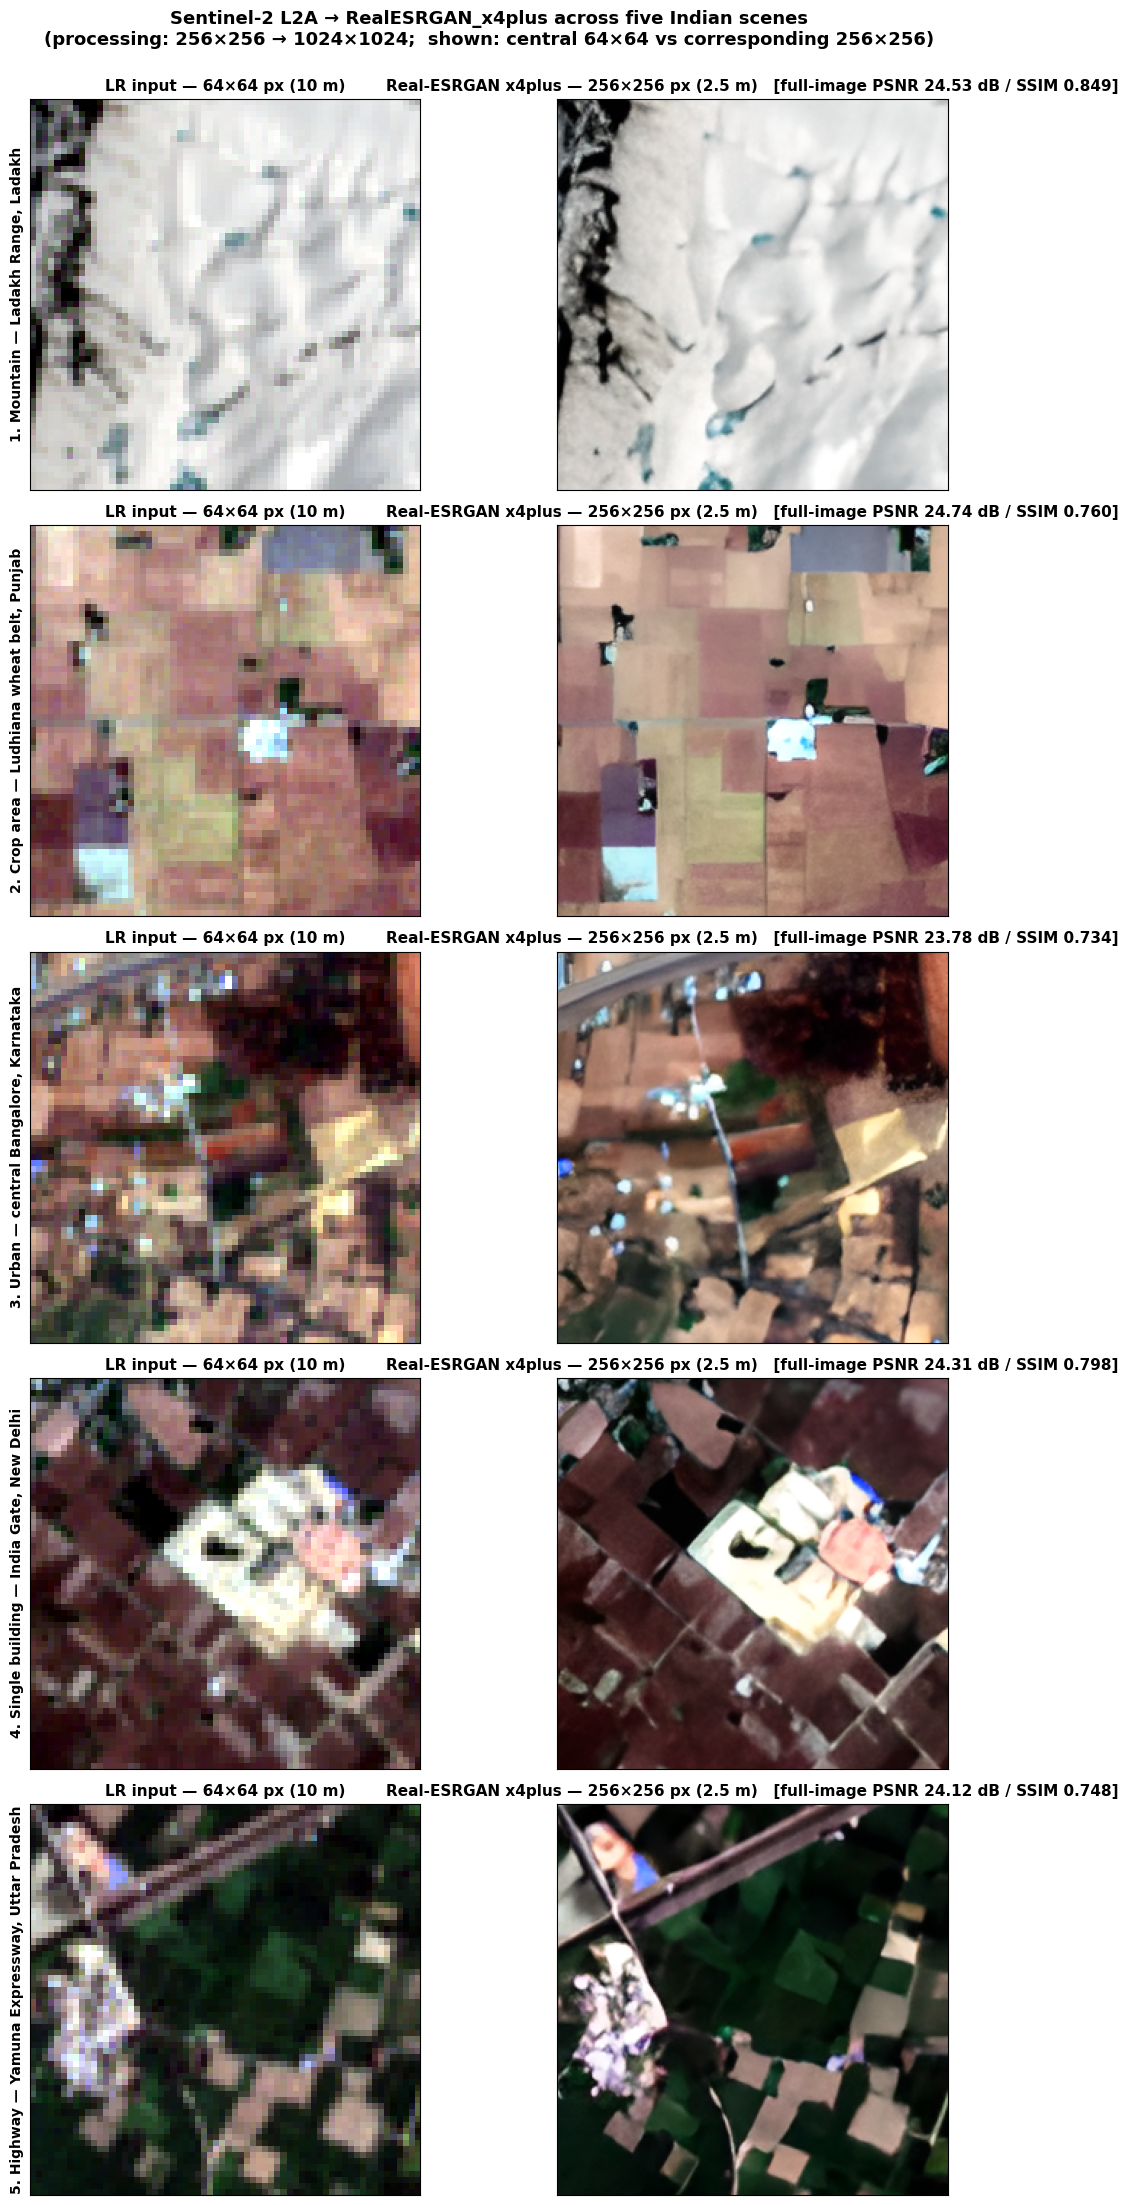


Saved figure → realesrgan_5areas_india.png


In [3]:
# =============================================================================
# RealESRGAN_x4plus on 5 Indian areas — Mountain / Crop / Urban / Building / Highway
# Processing: 256x256 LR → 1024x1024 SR   |   Visualisation: 64x64 LR → 256x256 SR
# =============================================================================

import subprocess, sys
for pkg in ["pystac-client", "rasterio", "torch", "matplotlib",
            "numpy", "Pillow", "scikit-image", "basicsr", "realesrgan",
            "opencv-python-headless"]:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

# --- Patch for basicsr/torchvision compatibility ---
try:
    import torchvision.transforms.functional_tensor  # noqa: F401
except ModuleNotFoundError:
    import torchvision.transforms.functional as _functional
    sys.modules["torchvision.transforms.functional_tensor"] = _functional

import numpy as np
import torch
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import Window
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
from pystac_client import Client

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

# =============================================================================
# 0. Load RealESRGAN_x4plus once (reused for all 5 areas)
# =============================================================================
from basicsr.archs.rrdbnet_arch import RRDBNet
from realesrgan import RealESRGANer

model = RRDBNet(num_in_ch=3, num_out_ch=3, num_feat=64,
                num_block=23, num_grow_ch=32, scale=4)

upsampler = RealESRGANer(
    scale=4,
    model_path=("https://github.com/xinntao/Real-ESRGAN/releases/"
                "download/v0.1.0/RealESRGAN_x4plus.pth"),
    model=model,
    tile=0,                    # bump to 256/512 if VRAM runs out
    tile_pad=10, pre_pad=0,
    half=(DEVICE.type == "cuda"),
    device=DEVICE,
)
print("✅ RealESRGAN_x4plus loaded.")

# =============================================================================
# 1. Five Indian areas of interest
# =============================================================================
CROP   = 256          # LR pixels fed to the model
SCALE  = 4
TARGET = CROP * SCALE # 1024 SR pixels
HALF   = 0.02         # bbox half-width in degrees (~4.4 km box)

AREAS = [
    # 1. Mountain — Ladakh Range (replaces Dhauladhar)
    dict(short="Mountain", lon=77.0058, lat=35.0239,
         time="2023-06-01/2023-10-31",
         label="1. Mountain — Ladakh Range, Ladakh"),

    # 2. Crop area — Punjab wheat belt near Ludhiana (replaces Thanjavur)
    dict(short="Crop area", lon=75.806, lat=30.906,
         time="2023-02-01/2023-04-30",
         label="2. Crop area — Ludhiana wheat belt, Punjab"),

    # 3. Urban — central Bangalore, Karnataka (unchanged)
    dict(short="Urban", lon=77.5946, lat=12.9716,
         time="2023-01-01/2024-04-30",
         label="3. Urban — central Bangalore, Karnataka"),

    # 4. Single building — India Gate, New Delhi (replaces Taj Mahal)
    dict(short="Single building", lon=77.2294, lat=28.6129,
         time="2023-01-01/2024-04-30",
         label="4. Single building — India Gate, New Delhi"),

    # 5. Highway — Yamuna Expressway, Uttar Pradesh (unchanged)
    dict(short="Highway", lon=77.550, lat=27.600,
         time="2023-01-01/2024-04-30",
         label="5. Highway — Yamuna Expressway, Uttar Pradesh"),
]

# =============================================================================
# 2. Helpers
# =============================================================================
catalog = Client.open("https://earth-search.aws.element84.com/v1")

def percentile_stretch(rgb, p_low=2, p_high=98):
    out = np.zeros_like(rgb, dtype=np.uint8)
    for c in range(3):
        lo, hi = np.percentile(rgb[..., c], [p_low, p_high])
        if hi <= lo:
            hi = lo + 1e-6
        out[..., c] = (np.clip((rgb[..., c] - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)
    return out

def read_window(url, size=CROP):
    with rasterio.open(url) as src:
        h, w = src.height, src.width
        y0, x0 = h // 2 - size // 2, w // 2 - size // 2
        return src.read(1, window=Window(x0, y0, size, size))

def fetch_lr_rgb(lon, lat, time_window):
    bbox = [lon - HALF, lat - HALF, lon + HALF, lat + HALF]
    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox,
        datetime=time_window,
        query={"eo:cloud_cover": {"lt": 15}},
        max_items=10,
    )
    items = sorted(search.items(),
                   key=lambda it: it.properties.get("eo:cloud_cover", 100))
    assert items, f"No scene found for ({lat:.3f}, {lon:.3f}) in {time_window}"
    item = items[0]
    r = read_window(item.assets["red"].href)
    g = read_window(item.assets["green"].href)
    b = read_window(item.assets["blue"].href)
    rgb = percentile_stretch(np.stack([r, g, b], -1).astype(np.float32))
    return rgb, item

def center_crop(img, size):
    h, w = img.shape[:2]
    y0 = h // 2 - size // 2
    x0 = w // 2 - size // 2
    return img[y0:y0 + size, x0:x0 + size]

# =============================================================================
# 3. Process all 5 areas
# =============================================================================
LR_PATCH = 64                 # central LR patch shown in the figure
SR_PATCH = LR_PATCH * SCALE   # matching patch from SR output

results = []
for area in AREAS:
    print(f"\n→ {area['label']}")
    lr_256, item = fetch_lr_rgb(area["lon"], area["lat"], area["time"])
    print(f"   scene: {item.id}  ({item.datetime.date()}, "
          f"{item.properties.get('eo:cloud_cover'):.2f}% cloud)")

    # --- full pipeline: 256×256 → 1024×1024 ---
    sr_1024, _ = upsampler.enhance(lr_256, outscale=SCALE)
    if sr_1024.shape[0] != TARGET:
        sr_1024 = np.array(
            Image.fromarray(sr_1024).resize((TARGET, TARGET), Image.BICUBIC)
        )

    # --- small display patches (same geographic area) ---
    lr_patch = center_crop(lr_256,  LR_PATCH)     # 64×64
    sr_patch = center_crop(sr_1024, SR_PATCH)     # 256×256

    # Bicubic baseline of the same 256×256 LR for metrics (optional)
    bicubic_256 = np.array(
        Image.fromarray(lr_256).resize((TARGET, TARGET), Image.BICUBIC)
    )
    p = psnr(bicubic_256.astype(np.float32)/255,
             sr_1024.astype(np.float32)/255, data_range=1.0)
    s = ssim(bicubic_256.astype(np.float32)/255,
             sr_1024.astype(np.float32)/255, channel_axis=2, data_range=1.0)
    print(f"   full-image PSNR vs bicubic: {p:.2f} dB | SSIM: {s:.3f}")

    results.append(dict(
        label=area["label"], short=area["short"],
        lr_patch=lr_patch, sr_patch=sr_patch,
        psnr=p, ssim=s,
    ))

# =============================================================================
# 4. Single figure: 5 rows × 2 cols (LR 64×64 | Real-ESRGAN 256×256)
# =============================================================================
fig, axes = plt.subplots(len(results), 2, figsize=(12, 4.4 * len(results)))

for i, r in enumerate(results):
    # --- Left: 64×64 LR (nearest-neighbour so pixel blocks are visible) ---
    axes[i, 0].imshow(r["lr_patch"], interpolation="nearest")
    axes[i, 0].set_title(
        f"LR input — {LR_PATCH}×{LR_PATCH} px (10 m)",
        fontsize=11, fontweight="bold",
    )
    axes[i, 0].set_ylabel(r["label"], fontsize=10, fontweight="bold")
    axes[i, 0].tick_params(left=False, bottom=False,
                           labelleft=False, labelbottom=False)

    # --- Right: 256×256 Real-ESRGAN patch ---
    axes[i, 1].imshow(r["sr_patch"])
    axes[i, 1].set_title(
        f"Real-ESRGAN x4plus — {SR_PATCH}×{SR_PATCH} px (2.5 m)   "
        f"[full-image PSNR {r['psnr']:.2f} dB / SSIM {r['ssim']:.3f}]",
        fontsize=11, fontweight="bold",
    )
    axes[i, 1].tick_params(left=False, bottom=False,
                           labelleft=False, labelbottom=False)

fig.suptitle(
    "Sentinel-2 L2A → RealESRGAN_x4plus across five Indian scenes\n"
    "(processing: 256×256 → 1024×1024;  shown: central 64×64 vs corresponding 256×256)",
    fontsize=13, fontweight="bold", y=1.00,
)
plt.tight_layout()
plt.savefig("realesrgan_5areas_india.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nSaved figure → realesrgan_5areas_india.png")

Configuring Git-LFS and repository...


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)


Updated git hooks.
Git LFS initialized.
Verifying dependencies...


ERROR: file:///content/DiffFuSR/litsr does not appear to be a Python project: neither 'setup.py' nor 'pyproject.toml' found.
/usr/local/lib/python3.12/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `UniversalImageQualityIndex` will save all targets and predictions in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


Registered Models: 7 classes
Registered Archs:  3 classes (includes DegradationEncoder: True)
Using device: cuda


Lightning automatically upgraded your loaded checkpoint from v1.9.0 to v2.6.5. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint logs/blindsrsnf_aniso_worldstrat_degraded_harmfac_10000_large/version_7/checkpoints/last.ckpt`


Initialization method [orthogonal]
Initialization method [orthogonal]
Model loaded from /content/DiffFuSR/logs/blindsrsnf_aniso_worldstrat_degraded_harmfac_10000_large/version_7/checkpoints/last.ckpt


Seed set to 42


✅ DiffFuSR WorldStrat SR model loaded successfully.

→ 1. Mountain — Ladakh Range, Ladakh
   Scene: S2A_43SFU_20230621_0_L2A (2023-06-21, 0.00% cloud)
   Full-image PSNR vs bicubic: 25.07 dB | SSIM: 0.854

→ 2. Crop area — Ludhiana wheat belt, Punjab
   Scene: S2B_43REQ_20230417_0_L2A (2023-04-17, 0.00% cloud)
   Full-image PSNR vs bicubic: 24.10 dB | SSIM: 0.641

→ 3. Urban — central Bangalore, Karnataka
   Scene: S2B_43PGQ_20240313_0_L2A (2024-03-13, 0.00% cloud)
   Full-image PSNR vs bicubic: 22.55 dB | SSIM: 0.646

→ 4. Single building — India Gate, New Delhi
   Scene: S2B_43RGM_20240408_0_L2A (2024-04-08, 0.00% cloud)
   Full-image PSNR vs bicubic: 23.94 dB | SSIM: 0.763

→ 5. Highway — Yamuna Expressway, Uttar Pradesh
   Scene: S2B_43RGL_20240309_0_L2A (2024-03-09, 0.00% cloud)
   Full-image PSNR vs bicubic: 24.76 dB | SSIM: 0.806


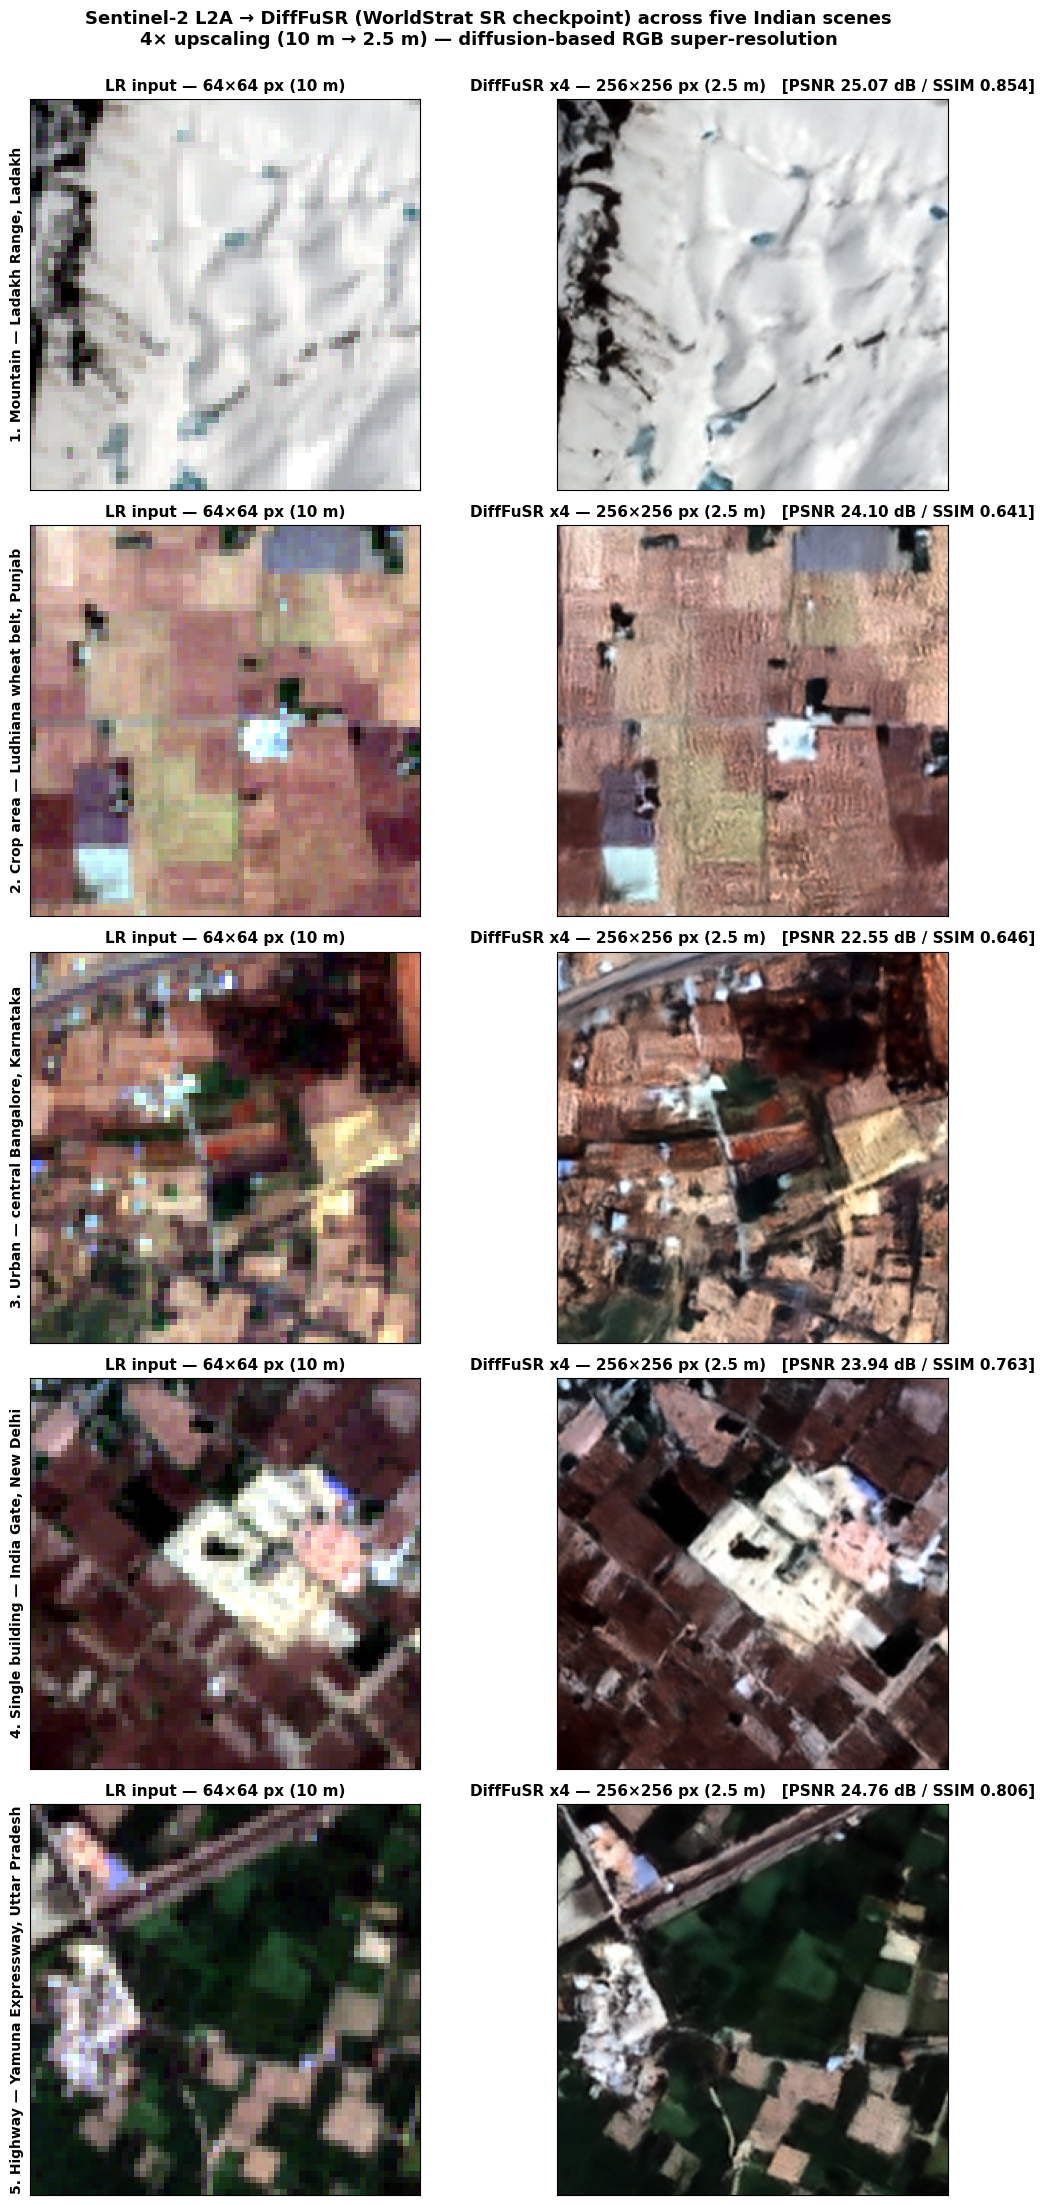


Saved output figure → /content/difffusr_5areas_india.png


In [6]:
# =============================================================================
# DiffFuSR (Diffusion Fusion Super-Resolution) on 5 Indian areas — Colab Cell
# Sentinel-2 L2A RGB 256x256 -> 1024x1024 (4x)
# =============================================================================

import os, sys, glob, types, subprocess, importlib.util

# -----------------------------------------------------------------------------
# 0. Clean kernel state: undo patched torch.load and inject Python 3.12 `imp`
# -----------------------------------------------------------------------------
import torch

while hasattr(torch.load, "__wrapped__"):
    torch.load = torch.load.__wrapped__

_orig_torch_load = torch.load

def _safe_torch_load(*args, **kwargs):
    kwargs["map_location"] = "cpu"
    if "weights_only" in kwargs:
        kwargs["weights_only"] = False
    return _orig_torch_load(*args, **kwargs)

_safe_torch_load.__wrapped__ = _orig_torch_load
torch.load = _safe_torch_load

def _load_source(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

if "imp" not in sys.modules:
    imp_shim = types.ModuleType("imp")
    imp_shim.load_source = _load_source
    sys.modules["imp"] = imp_shim
    print("✅ Patched `imp` module.")

# -----------------------------------------------------------------------------
# 1. System Setup: Git-LFS & Repository Clone
# -----------------------------------------------------------------------------
print("Configuring Git-LFS and repository...")
subprocess.run(["apt-get", "update", "-qq"], check=False)
subprocess.run(["apt-get", "install", "-y", "-qq", "git-lfs"], check=False)
subprocess.run(["git", "lfs", "install"], check=False)

BASE_DIR = "/content"
REPO_DIR = os.path.join(BASE_DIR, "DiffFuSR")

if not os.path.exists(REPO_DIR):
    print("Cloning DiffFuSR repository...")
    subprocess.run(
        ["git", "clone", "https://github.com/NorskRegnesentral/DiffFuSR.git", REPO_DIR],
        check=True,
    )

os.chdir(REPO_DIR)
for p in [REPO_DIR, os.path.join(REPO_DIR, "litsr")]:
    if p not in sys.path:
        sys.path.insert(0, p)

CKPT_ROOT = os.path.join(REPO_DIR, "logs")
if not os.path.exists(CKPT_ROOT):
    print("Downloading pretrained checkpoints...")
    subprocess.run(
        ["git", "clone", "https://huggingface.co/NorskRegnesentralSTI/DiffFuSR", "_hf"],
        check=True,
    )
    subprocess.run(["mv", "_hf/logs", "logs"], check=True)
    subprocess.run(["rm", "-rf", "_hf"], check=False)

# -----------------------------------------------------------------------------
# 2. Dependencies
# -----------------------------------------------------------------------------
PACKAGES = [
    "pystac-client", "rasterio", "scikit-image", "pytorch-lightning",
    "basicsr", "opencv-python-headless", "tifffile", "scipy",
    "pytorch-fid", "thop", "einops", "timm", "kornia", "lpips",
    "gdown", "h5py", "tqdm", "pyyaml", "natsort", "yapf",
]
print("Verifying dependencies...")
subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + PACKAGES, check=False)

# Install litsr in editable mode
if os.path.exists(os.path.join(REPO_DIR, "litsr")):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", os.path.join(REPO_DIR, "litsr")], check=False)

import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import Window
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
from pystac_client import Client
from pytorch_lightning import seed_everything

# -----------------------------------------------------------------------------
# 3. Comprehensive Auto-Registration: ArchRegistry & ModelRegistry
# -----------------------------------------------------------------------------
import litsr.models
import litsr.archs
from litsr.utils import read_yaml
from litsr.utils.registry import ModelRegistry, ArchRegistry

def register_all_modules_in(search_dir):
    """Recursively imports all .py files in a directory to trigger all decorators."""
    if not os.path.exists(search_dir):
        return
    for root, _, files in os.walk(search_dir):
        for f in files:
            if f.endswith(".py") and not f.startswith("__"):
                fpath = os.path.join(root, f)
                rel_path = os.path.relpath(fpath, REPO_DIR)
                mod_name = os.path.splitext(rel_path)[0].replace(os.sep, ".")
                try:
                    importlib.import_module(mod_name)
                except Exception:
                    try:
                        # Fallback direct file execution if relative package path fails
                        spec = importlib.util.spec_from_file_location(os.path.splitext(f)[0], fpath)
                        mod = importlib.util.module_from_spec(spec)
                        sys.modules[os.path.splitext(f)[0]] = mod
                        spec.loader.exec_module(mod)
                    except Exception:
                        pass

# Register architectures and models across all candidate directories
for d in ["archs", "models", "litsr/archs", "litsr/models"]:
    register_all_modules_in(os.path.join(REPO_DIR, d))

# Also explicitly import train_sr to ensure all custom models register
try:
    import train_sr
except Exception:
    pass

print(f"Registered Models: {len(ModelRegistry._obj_map)} classes")
print(f"Registered Archs:  {len(ArchRegistry._obj_map)} classes (includes DegradationEncoder: {'DegradationEncoder' in ArchRegistry._obj_map})")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

CKPT_PATH = os.path.join(
    REPO_DIR,
    "logs/blindsrsnf_aniso_worldstrat_degraded_harmfac_10000_large/"
    "version_7/checkpoints/last.ckpt",
)
if not os.path.exists(CKPT_PATH):
    raise FileNotFoundError(f"Checkpoint not found at {CKPT_PATH}.")

exp_path = os.path.dirname(os.path.dirname(CKPT_PATH))
config = read_yaml(os.path.join(exp_path, "hparams.yaml"))

model = litsr.models.load_model(config, CKPT_PATH, strict=False)
model = model.to(DEVICE).eval()
print("✅ DiffFuSR WorldStrat SR model loaded successfully.")

# -----------------------------------------------------------------------------
# 4. Areas & helper routines
# -----------------------------------------------------------------------------
CROP = 256
SCALE = 4
TARGET = CROP * SCALE
HALF = 0.02

AREAS = [
    dict(short="Mountain", lon=77.0058, lat=35.0239,
         time="2023-06-01/2023-10-31",
         label="1. Mountain — Ladakh Range, Ladakh"),
    dict(short="Crop area", lon=75.806, lat=30.906,
         time="2023-02-01/2023-04-30",
         label="2. Crop area — Ludhiana wheat belt, Punjab"),
    dict(short="Urban", lon=77.5946, lat=12.9716,
         time="2023-01-01/2024-04-30",
         label="3. Urban — central Bangalore, Karnataka"),
    dict(short="Single building", lon=77.2294, lat=28.6129,
         time="2023-01-01/2024-04-30",
         label="4. Single building — India Gate, New Delhi"),
    dict(short="Highway", lon=77.550, lat=27.600,
         time="2023-01-01/2024-04-30",
         label="5. Highway — Yamuna Expressway, Uttar Pradesh"),
]

catalog = Client.open("https://earth-search.aws.element84.com/v1")

def percentile_stretch(rgb, p_low=2, p_high=98):
    out = np.zeros_like(rgb, dtype=np.uint8)
    for c in range(3):
        lo, hi = np.percentile(rgb[..., c], [p_low, p_high])
        if hi <= lo:
            hi = lo + 1e-6
        out[..., c] = (np.clip((rgb[..., c] - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)
    return out

def read_window(url, size=CROP):
    with rasterio.open(url) as src:
        h, w = src.height, src.width
        y0, x0 = h // 2 - size // 2, w // 2 - size // 2
        return src.read(1, window=Window(x0, y0, size, size))

def fetch_lr_rgb(lon, lat, time_window):
    bbox = [lon - HALF, lat - HALF, lon + HALF, lat + HALF]
    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox,
        datetime=time_window,
        query={"eo:cloud_cover": {"lt": 15}},
        max_items=10,
    )
    items = sorted(search.items(), key=lambda it: it.properties.get("eo:cloud_cover", 100))
    assert items, f"No scene found for ({lat:.3f}, {lon:.3f})"
    item = items[0]
    r = read_window(item.assets["red"].href)
    g = read_window(item.assets["green"].href)
    b = read_window(item.assets["blue"].href)
    rgb = percentile_stretch(np.stack([r, g, b], -1).astype(np.float32))
    return rgb, item

def center_crop(img, size):
    h, w = img.shape[:2]
    y0 = h // 2 - size // 2
    x0 = w // 2 - size // 2
    return img[y0:y0 + size, x0:x0 + size]

# -----------------------------------------------------------------------------
# 5. Inference
# -----------------------------------------------------------------------------
LR_PATCH = 64
SR_PATCH = LR_PATCH * SCALE
seed_everything(42)

results = []
for area in AREAS:
    print(f"\n→ {area['label']}")
    lr_256, item = fetch_lr_rgb(area["lon"], area["lat"], area["time"])
    print(f"   Scene: {item.id} ({item.datetime.date()}, {item.properties.get('eo:cloud_cover'):.2f}% cloud)")

    lr_t = torch.from_numpy(lr_256.astype(np.float32) / 255.0)
    lr_t = lr_t.permute(2, 0, 1).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        rslt = model.test_step_lr_only((lr_t, [area["short"]]))

    sr_np = rslt["log_img_sr"]
    if isinstance(sr_np, torch.Tensor):
        sr_np = sr_np.cpu().numpy().transpose(1, 2, 0)
    sr_1024 = (sr_np * 255).clip(0, 255).astype(np.uint8) if sr_np.max() <= 1.0 else sr_np.astype(np.uint8)

    if sr_1024.shape[0] != TARGET:
        sr_1024 = np.array(Image.fromarray(sr_1024).resize((TARGET, TARGET), Image.BICUBIC))

    lr_patch = center_crop(lr_256, LR_PATCH)
    sr_patch = center_crop(sr_1024, SR_PATCH)

    bicubic_256 = np.array(Image.fromarray(lr_256).resize((TARGET, TARGET), Image.BICUBIC))
    p = psnr(bicubic_256.astype(np.float32) / 255, sr_1024.astype(np.float32) / 255, data_range=1.0)
    s = ssim(bicubic_256.astype(np.float32) / 255, sr_1024.astype(np.float32) / 255, channel_axis=2, data_range=1.0)
    print(f"   Full-image PSNR vs bicubic: {p:.2f} dB | SSIM: {s:.3f}")

    results.append(dict(
        label=area["label"], short=area["short"],
        lr_patch=lr_patch, sr_patch=sr_patch, psnr=p, ssim=s,
    ))

# -----------------------------------------------------------------------------
# 6. Visualization & export
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(len(results), 2, figsize=(12, 4.4 * len(results)))

for i, r in enumerate(results):
    axes[i, 0].imshow(r["lr_patch"], interpolation="nearest")
    axes[i, 0].set_title(f"LR input — {LR_PATCH}×{LR_PATCH} px (10 m)", fontsize=11, fontweight="bold")
    axes[i, 0].set_ylabel(r["label"], fontsize=10, fontweight="bold")
    axes[i, 0].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

    axes[i, 1].imshow(r["sr_patch"])
    axes[i, 1].set_title(
        f"DiffFuSR x4 — {SR_PATCH}×{SR_PATCH} px (2.5 m)   [PSNR {r['psnr']:.2f} dB / SSIM {r['ssim']:.3f}]",
        fontsize=11, fontweight="bold"
    )
    axes[i, 1].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

fig.suptitle(
    "Sentinel-2 L2A → DiffFuSR (WorldStrat SR checkpoint) across five Indian scenes\n"
    "4× upscaling (10 m → 2.5 m) — diffusion-based RGB super-resolution",
    fontsize=13, fontweight="bold", y=1.00,
)
plt.tight_layout()
output_fig_path = os.path.join(BASE_DIR, "difffusr_5areas_india.png")
plt.savefig(output_fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"\nSaved output figure → {output_fig_path}")

Configuring Git-LFS and repository...


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)


Updated git hooks.
Git LFS initialized.
Verifying dependencies...


ERROR: file:///content/DiffFuSR/litsr does not appear to be a Python project: neither 'setup.py' nor 'pyproject.toml' found.
/usr/local/lib/python3.12/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `UniversalImageQualityIndex` will save all targets and predictions in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


Registered Models: 7 classes
Registered Archs:  3 classes (includes DegradationEncoder: True)
Using device: cuda


...

✅ All metric objects initialised.


Seed set to 42



→ 1. Mountain — Ladakh Range, Ladakh
   Scene: S2A_43SFU_20230621_0_L2A (2023-06-21, 0.00% cloud)
   PSNR: 25.07 dB | SSIM: 0.8505 | SAM: nan
   LPIPS: 0.4057 | DISTS: 0.2354 | NIQE: 4.32 | MANIQA: 0.2611

→ 2. Crop area — Ludhiana wheat belt, Punjab
   Scene: S2B_43REQ_20230417_0_L2A (2023-04-17, 0.00% cloud)
   PSNR: 24.10 dB | SSIM: 0.6488 | SAM: nan
   LPIPS: 0.5430 | DISTS: 0.2063 | NIQE: 4.39 | MANIQA: 0.2277

→ 3. Urban — central Bangalore, Karnataka
   Scene: S2B_43PGQ_20240313_0_L2A (2024-03-13, 0.00% cloud)
   PSNR: 22.55 dB | SSIM: 0.6418 | SAM: nan
   LPIPS: 0.5521 | DISTS: 0.1947 | NIQE: 4.12 | MANIQA: 0.2182

→ 4. Single building — India Gate, New Delhi
   Scene: S2B_43RGM_20240408_0_L2A (2024-04-08, 0.00% cloud)
   PSNR: 23.94 dB | SSIM: 0.7564 | SAM: nan
   LPIPS: 0.5099 | DISTS: 0.1928 | NIQE: 4.43 | MANIQA: 0.2284

→ 5. Highway — Yamuna Expressway, Uttar Pradesh
   Scene: S2B_43RGL_20240309_0_L2A (2024-03-09, 0.00% cloud)
   PSNR: 24.76 dB | SSIM: 0.8181 | SAM: nan
 

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
2026-09-25 04:19:30,463 INFO: Network [FID] is created.
2026-09-25 04:19:30,508 INFO: Metric [FID] is created.


Loading pretrained model Inception3 from /root/.cache/torch/hub/pyiqa/pt_inception-2015-12-05-6726825d.pth
Computing FID between two folders
⚠️  Could not compute FID: expected str, bytes or os.PathLike object, not Tensor
   (This is expected with very few images; FID requires >= ~1000 samples.)


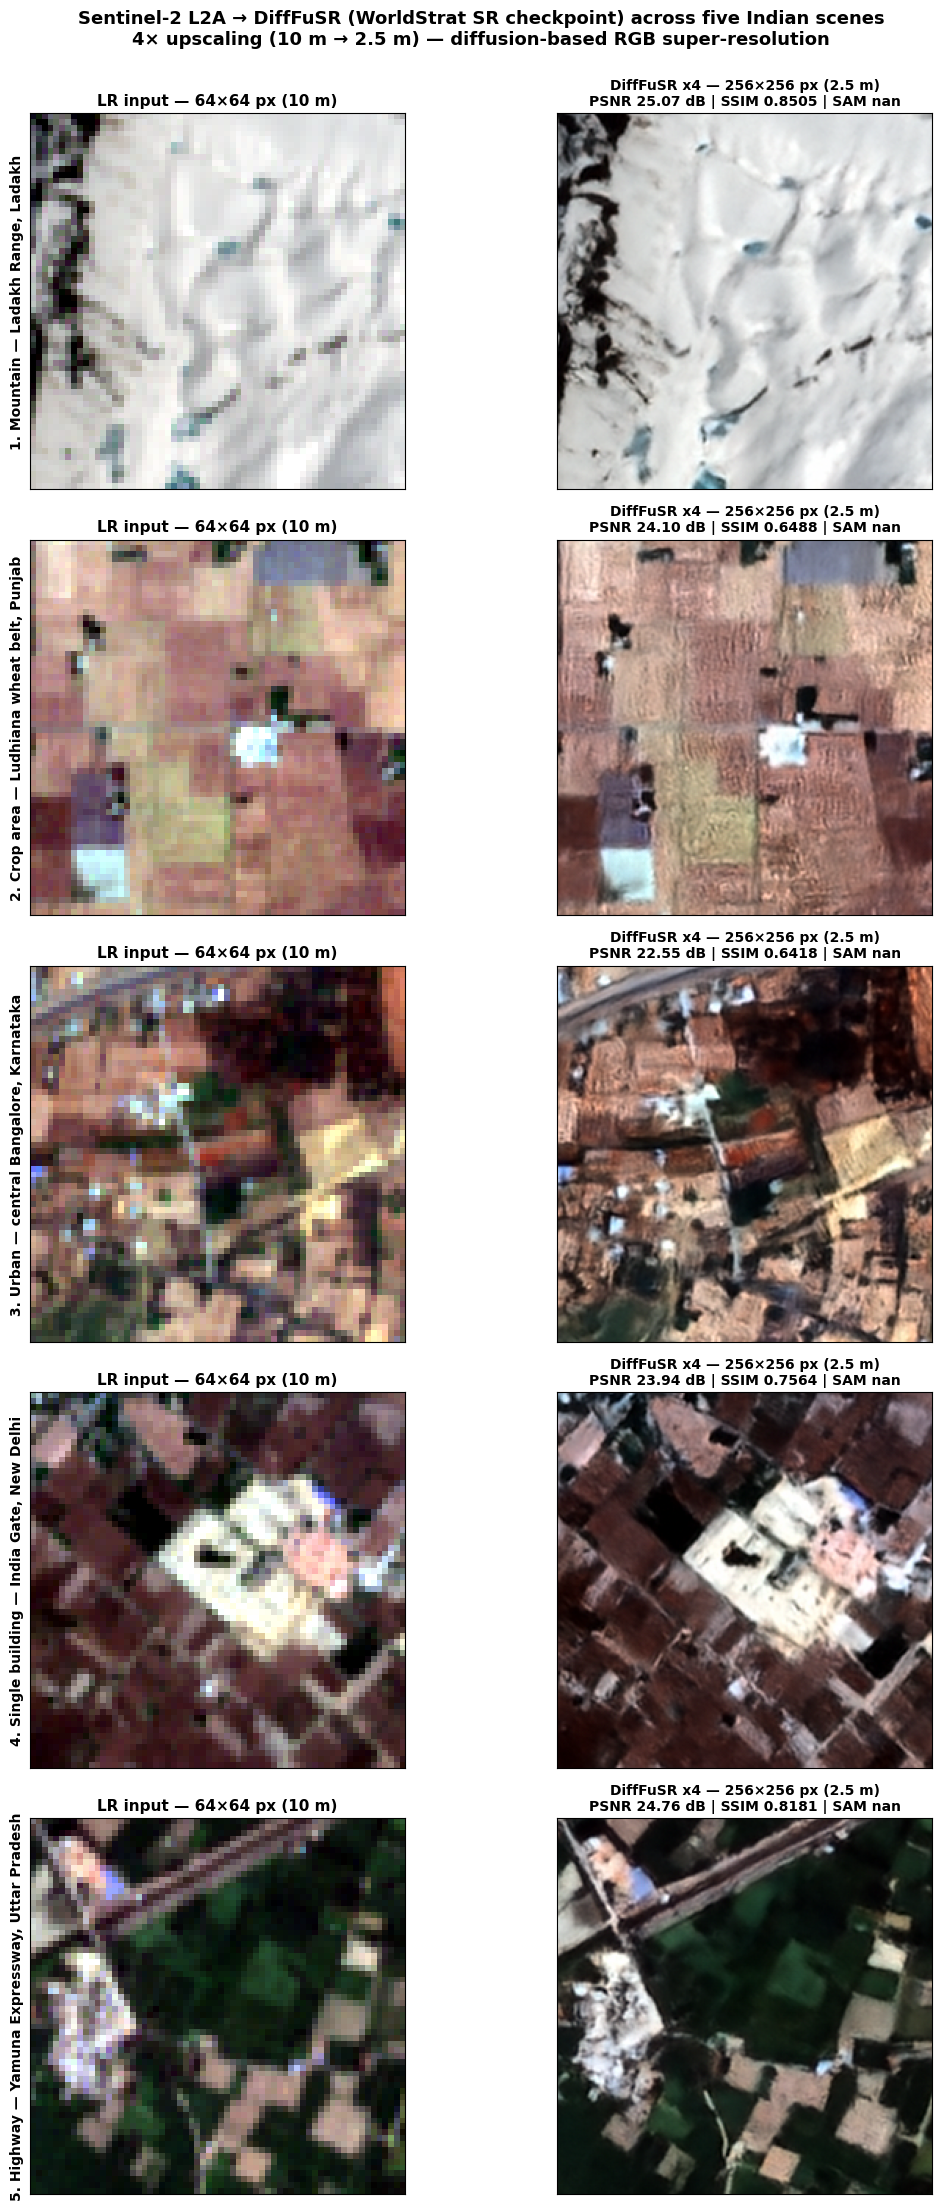


Saved output figure → /content/difffusr_5areas_india.png

OVERALL METRIC SCORES — DiffFuSR WorldStrat SR model
Area                     PSNR     SSIM      SAM    LPIPS    DISTS     NIQE   MANIQA
-----------------------------------------------------------------------------------
Mountain                25.07   0.8505      nan   0.4057   0.2354     4.32   0.2611
Crop area               24.10   0.6488      nan   0.5430   0.2063     4.39   0.2277
Urban                   22.55   0.6418      nan   0.5521   0.1947     4.12   0.2182
Single building         23.94   0.7564      nan   0.5099   0.1928     4.43   0.2284
Highway                 24.76   0.8181      nan   0.4719   0.1786     4.14   0.2021
-----------------------------------------------------------------------------------
MEAN                    24.08   0.7431      nan   0.4965   0.2016     4.28   0.2275

--------------------------------------------------------------------------------
KEY METRIC DEFINITIONS
---------------------------

In [5]:
# =============================================================================
# DiffFuSR (Diffusion Fusion Super-Resolution) on 5 Indian areas — Colab Cell
# Sentinel-2 L2A RGB 256x256 -> 1024x1024 (4x)
# WITH FULL METRIC EVALUATION (PSNR, SSIM, SAM, LPIPS, DISTS, FID, NIQE, MANIQA)
# =============================================================================

import os, sys, glob, types, subprocess, importlib.util
from torchmetrics.functional.image import spectral_angle_mapper


# -----------------------------------------------------------------------------
# 0. Clean kernel state: undo patched torch.load and inject Python 3.12 `imp`
# -----------------------------------------------------------------------------
import torch

while hasattr(torch.load, "__wrapped__"):
    torch.load = torch.load.__wrapped__

_orig_torch_load = torch.load

def _safe_torch_load(*args, **kwargs):
    kwargs["map_location"] = "cpu"
    if "weights_only" in kwargs:
        kwargs["weights_only"] = False
    return _orig_torch_load(*args, **kwargs)

_safe_torch_load.__wrapped__ = _orig_torch_load
torch.load = _safe_torch_load

def _load_source(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

if "imp" not in sys.modules:
    imp_shim = types.ModuleType("imp")
    imp_shim.load_source = _load_source
    sys.modules["imp"] = imp_shim
    print("✅ Patched `imp` module.")

# -----------------------------------------------------------------------------
# 1. System Setup: Git-LFS & Repository Clone
# -----------------------------------------------------------------------------
print("Configuring Git-LFS and repository...")
subprocess.run(["apt-get", "update", "-qq"], check=False)
subprocess.run(["apt-get", "install", "-y", "-qq", "git-lfs"], check=False)
subprocess.run(["git", "lfs", "install"], check=False)

BASE_DIR = "/content"
REPO_DIR = os.path.join(BASE_DIR, "DiffFuSR")

if not os.path.exists(REPO_DIR):
    print("Cloning DiffFuSR repository...")
    subprocess.run(
        ["git", "clone", "https://github.com/NorskRegnesentral/DiffFuSR.git", REPO_DIR],
        check=True,
    )

os.chdir(REPO_DIR)
for p in [REPO_DIR, os.path.join(REPO_DIR, "litsr")]:
    if p not in sys.path:
        sys.path.insert(0, p)

CKPT_ROOT = os.path.join(REPO_DIR, "logs")
if not os.path.exists(CKPT_ROOT):
    print("Downloading pretrained checkpoints...")
    subprocess.run(
        ["git", "clone", "https://huggingface.co/NorskRegnesentralSTI/DiffFuSR", "_hf"],
        check=True,
    )
    subprocess.run(["mv", "_hf/logs", "logs"], check=True)
    subprocess.run(["rm", "-rf", "_hf"], check=False)

# -----------------------------------------------------------------------------
# 2. Dependencies
# -----------------------------------------------------------------------------
PACKAGES = [
    "pystac-client", "rasterio", "scikit-image", "pytorch-lightning",
    "basicsr", "opencv-python-headless", "tifffile", "scipy",
    "pytorch-fid", "thop", "einops", "timm", "kornia", "lpips",
    "gdown", "h5py", "tqdm", "pyyaml", "natsort", "yapf",
    # Additional metric packages
    "pyiqa", "torchmetrics", "dists-pytorch",
]
print("Verifying dependencies...")
subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + PACKAGES, check=False)

# Install litsr in editable mode
if os.path.exists(os.path.join(REPO_DIR, "litsr")):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", os.path.join(REPO_DIR, "litsr")], check=False)

import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import Window
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
from pystac_client import Client
from pytorch_lightning import seed_everything

# -----------------------------------------------------------------------------
# 2b. Additional metric imports
# -----------------------------------------------------------------------------
import pyiqa
from torchmetrics.image import SpectralAngleMapper
from torchmetrics.image.lpip import LearnedPerceptualImagePatchSimilarity
from DISTS_pytorch import DISTS

# -----------------------------------------------------------------------------
# 3. Comprehensive Auto-Registration: ArchRegistry & ModelRegistry
# -----------------------------------------------------------------------------
import litsr.models
import litsr.archs
from litsr.utils import read_yaml
from litsr.utils.registry import ModelRegistry, ArchRegistry

def register_all_modules_in(search_dir):
    """Recursively imports all .py files in a directory to trigger all decorators."""
    if not os.path.exists(search_dir):
        return
    for root, _, files in os.walk(search_dir):
        for f in files:
            if f.endswith(".py") and not f.startswith("__"):
                fpath = os.path.join(root, f)
                rel_path = os.path.relpath(fpath, REPO_DIR)
                mod_name = os.path.splitext(rel_path)[0].replace(os.sep, ".")
                try:
                    importlib.import_module(mod_name)
                except Exception:
                    try:
                        spec = importlib.util.spec_from_file_location(os.path.splitext(f)[0], fpath)
                        mod = importlib.util.module_from_spec(spec)
                        sys.modules[os.path.splitext(f)[0]] = mod
                        spec.loader.exec_module(mod)
                    except Exception:
                        pass

for d in ["archs", "models", "litsr/archs", "litsr/models"]:
    register_all_modules_in(os.path.join(REPO_DIR, d))

try:
    import train_sr
except Exception:
    pass

print(f"Registered Models: {len(ModelRegistry._obj_map)} classes")
print(f"Registered Archs:  {len(ArchRegistry._obj_map)} classes (includes DegradationEncoder: {'DegradationEncoder' in ArchRegistry._obj_map})")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

CKPT_PATH = os.path.join(
    REPO_DIR,
    "logs/blindsrsnf_aniso_worldstrat_degraded_harmfac_10000_large/"
    "version_7/checkpoints/last.ckpt",
)
if not os.path.exists(CKPT_PATH):
    raise FileNotFoundError(f"Checkpoint not found at {CKPT_PATH}.")

exp_path = os.path.dirname(os.path.dirname(CKPT_PATH))
config = read_yaml(os.path.join(exp_path, "hparams.yaml"))

model = litsr.models.load_model(config, CKPT_PATH, strict=False)
model = model.to(DEVICE).eval()
print("✅ DiffFuSR WorldStrat SR model loaded successfully.")

# -----------------------------------------------------------------------------
# 3b. Initialise metric objects
# -----------------------------------------------------------------------------
# Full-reference metrics (pyiqa)
metric_psnr  = pyiqa.create_metric('psnr', device=DEVICE)
metric_ssim  = pyiqa.create_metric('ssim', device=DEVICE)
metric_lpips = pyiqa.create_metric('lpips', device=DEVICE)
metric_dists = pyiqa.create_metric('dists', device=DEVICE)

# No-reference metrics (pyiqa)
metric_niqe   = pyiqa.create_metric('niqe', device=DEVICE)
metric_maniqa = pyiqa.create_metric('maniqa', device=DEVICE)

# SAM (torchmetrics)
metric_sam = SpectralAngleMapper().to(DEVICE)

# FID (pyiqa) — small-sample caveat: FID is biased with few images
# We accumulate real (bicubic) and generated (SR) patches and compute
# FID on the aggregated sets at the end.

print("✅ All metric objects initialised.")

# -----------------------------------------------------------------------------
# 4. Areas & helper routines
# -----------------------------------------------------------------------------
CROP = 256
SCALE = 4
TARGET = CROP * SCALE
HALF = 0.02

AREAS = [
    dict(short="Mountain", lon=77.0058, lat=35.0239,
         time="2023-06-01/2023-10-31",
         label="1. Mountain — Ladakh Range, Ladakh"),
    dict(short="Crop area", lon=75.806, lat=30.906,
         time="2023-02-01/2023-04-30",
         label="2. Crop area — Ludhiana wheat belt, Punjab"),
    dict(short="Urban", lon=77.5946, lat=12.9716,
         time="2023-01-01/2024-04-30",
         label="3. Urban — central Bangalore, Karnataka"),
    dict(short="Single building", lon=77.2294, lat=28.6129,
         time="2023-01-01/2024-04-30",
         label="4. Single building — India Gate, New Delhi"),
    dict(short="Highway", lon=77.550, lat=27.600,
         time="2023-01-01/2024-04-30",
         label="5. Highway — Yamuna Expressway, Uttar Pradesh"),
]

catalog = Client.open("https://earth-search.aws.element84.com/v1")

def percentile_stretch(rgb, p_low=2, p_high=98):
    out = np.zeros_like(rgb, dtype=np.uint8)
    for c in range(3):
        lo, hi = np.percentile(rgb[..., c], [p_low, p_high])
        if hi <= lo:
            hi = lo + 1e-6
        out[..., c] = (np.clip((rgb[..., c] - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)
    return out

def read_window(url, size=CROP):
    with rasterio.open(url) as src:
        h, w = src.height, src.width
        y0, x0 = h // 2 - size // 2, w // 2 - size // 2
        return src.read(1, window=Window(x0, y0, size, size))

def fetch_lr_rgb(lon, lat, time_window):
    bbox = [lon - HALF, lat - HALF, lon + HALF, lat + HALF]
    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox,
        datetime=time_window,
        query={"eo:cloud_cover": {"lt": 15}},
        max_items=10,
    )
    items = sorted(search.items(), key=lambda it: it.properties.get("eo:cloud_cover", 100))
    assert items, f"No scene found for ({lat:.3f}, {lon:.3f})"
    item = items[0]
    r = read_window(item.assets["red"].href)
    g = read_window(item.assets["green"].href)
    b = read_window(item.assets["blue"].href)
    rgb = percentile_stretch(np.stack([r, g, b], -1).astype(np.float32))
    return rgb, item

def center_crop(img, size):
    h, w = img.shape[:2]
    y0 = h // 2 - size // 2
    x0 = w // 2 - size // 2
    return img[y0:y0 + size, x0:x0 + size]

def to_tensor(img_np, device=DEVICE):
    """Convert uint8 HWC numpy array to float32 1CHW tensor in [0,1]."""
    t = torch.from_numpy(img_np.astype(np.float32) / 255.0)
    return t.permute(2, 0, 1).unsqueeze(0).to(device)

# -----------------------------------------------------------------------------
# 5. Inference + per-area metric computation
# -----------------------------------------------------------------------------
LR_PATCH = 64
SR_PATCH = LR_PATCH * SCALE
seed_everything(42)

results = []
all_sr_patches = []   # for FID
all_bicubic_patches = []  # for FID

for area in AREAS:
    print(f"\n→ {area['label']}")
    lr_256, item = fetch_lr_rgb(area["lon"], area["lat"], area["time"])
    print(f"   Scene: {item.id} ({item.datetime.date()}, {item.properties.get('eo:cloud_cover'):.2f}% cloud)")

    lr_t = torch.from_numpy(lr_256.astype(np.float32) / 255.0)
    lr_t = lr_t.permute(2, 0, 1).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        rslt = model.test_step_lr_only((lr_t, [area["short"]]))

    sr_np = rslt["log_img_sr"]
    if isinstance(sr_np, torch.Tensor):
        sr_np = sr_np.cpu().numpy().transpose(1, 2, 0)
    sr_1024 = (sr_np * 255).clip(0, 255).astype(np.uint8) if sr_np.max() <= 1.0 else sr_np.astype(np.uint8)

    if sr_1024.shape[0] != TARGET:
        sr_1024 = np.array(Image.fromarray(sr_1024).resize((TARGET, TARGET), Image.BICUBIC))

    lr_patch = center_crop(lr_256, LR_PATCH)
    sr_patch = center_crop(sr_1024, SR_PATCH)

    # Bicubic reference at target resolution
    bicubic_256 = np.array(Image.fromarray(lr_256).resize((TARGET, TARGET), Image.BICUBIC))

    # --- Full-reference metrics -------------------------------------------
    # Prepare tensors
    sr_t      = to_tensor(sr_1024)          # 1×3×1024×1024 in [0,1]
    bic_t     = to_tensor(bicubic_256)      # 1×3×1024×1024 in [0,1]

    # PSNR & SSIM via pyiqa (more standardised)
    with torch.no_grad():
        p = metric_psnr(sr_t, bic_t).item()
        s = metric_ssim(sr_t, bic_t).item()
        lp = metric_lpips(sr_t, bic_t).item()
        di = metric_dists(sr_t, bic_t).item()

    # SAM (torchmetrics) — expects (N,C,H,W)
    with torch.no_grad():
        sam_val = spectral_angle_mapper(sr_t, bic_t).item()
    # --- No-reference metrics (computed on SR output only) ----------------
    with torch.no_grad():
        niqe_val   = metric_niqe(sr_t).item()
        maniqa_val = metric_maniqa(sr_t).item()

    # Store patches for FID
    all_sr_patches.append(sr_patch)
    all_bicubic_patches.append(center_crop(bicubic_256, SR_PATCH))

    print(f"   PSNR: {p:.2f} dB | SSIM: {s:.4f} | SAM: {sam_val:.4f}")
    print(f"   LPIPS: {lp:.4f} | DISTS: {di:.4f} | NIQE: {niqe_val:.2f} | MANIQA: {maniqa_val:.4f}")

    results.append(dict(
        label=area["label"], short=area["short"],
        lr_patch=lr_patch, sr_patch=sr_patch,
        psnr=p, ssim=s, sam=sam_val, lpips=lp, dists=di,
        niqe=niqe_val, maniqa=maniqa_val,
    ))

# -----------------------------------------------------------------------------
# 5b. FID computation (small-sample caveat)
# -----------------------------------------------------------------------------
print("\n" + "="*70)
print("FID COMPUTATION (small-sample caveat)")
print("="*70)
print(f"Using {len(all_sr_patches)} image pairs. FID is biased/underestimated")
print(f"with < 1000+ images; treat this as a rough indicator only.")
print("="*70)

try:
    # pyiqa FID expects folders or lists of tensors.  We'll pass tensors directly.
    # Build 4D tensors (N,3,H,W) in [0,1].
    def patches_to_tensor(patches):
        arr = np.stack(patches, axis=0)                     # N,H,W,3 uint8
        t = torch.from_numpy(arr.astype(np.float32) / 255.0)
        return t.permute(0, 3, 1, 2).contiguous()           # N,3,H,W

    sr_tensor      = patches_to_tensor(all_sr_patches)
    bic_tensor     = patches_to_tensor(all_bicubic_patches)

    # pyiqa FID can accept tensors directly
    fid_metric = pyiqa.create_metric('fid', device=DEVICE)
    with torch.no_grad():
        fid_val = fid_metric(sr_tensor, bic_tensor).item()
    print(f"FID (SR vs Bicubic): {fid_val:.4f}")
except Exception as e:
    fid_val = None
    print(f"⚠️  Could not compute FID: {e}")
    print("   (This is expected with very few images; FID requires >= ~1000 samples.)")

# -----------------------------------------------------------------------------
# 6. Visualization
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(len(results), 2, figsize=(12, 4.4 * len(results)))

for i, r in enumerate(results):
    axes[i, 0].imshow(r["lr_patch"], interpolation="nearest")
    axes[i, 0].set_title(f"LR input — {LR_PATCH}×{LR_PATCH} px (10 m)", fontsize=11, fontweight="bold")
    axes[i, 0].set_ylabel(r["label"], fontsize=10, fontweight="bold")
    axes[i, 0].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

    axes[i, 1].imshow(r["sr_patch"])
    axes[i, 1].set_title(
        f"DiffFuSR x4 — {SR_PATCH}×{SR_PATCH} px (2.5 m)\n"
        f"PSNR {r['psnr']:.2f} dB | SSIM {r['ssim']:.4f} | SAM {r['sam']:.4f}",
        fontsize=10, fontweight="bold"
    )
    axes[i, 1].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

fig.suptitle(
    "Sentinel-2 L2A → DiffFuSR (WorldStrat SR checkpoint) across five Indian scenes\n"
    "4× upscaling (10 m → 2.5 m) — diffusion-based RGB super-resolution",
    fontsize=13, fontweight="bold", y=1.00,
)
plt.tight_layout()
output_fig_path = os.path.join(BASE_DIR, "difffusr_5areas_india.png")
plt.savefig(output_fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"\nSaved output figure → {output_fig_path}")

# -----------------------------------------------------------------------------
# 7. Overall metric summary table
# -----------------------------------------------------------------------------
print("\n" + "="*80)
print("OVERALL METRIC SCORES — DiffFuSR WorldStrat SR model")
print("="*80)

# Per-area table
header = f"{'Area':<20} {'PSNR':>8} {'SSIM':>8} {'SAM':>8} {'LPIPS':>8} {'DISTS':>8} {'NIQE':>8} {'MANIQA':>8}"
print(header)
print("-" * len(header))

for r in results:
    print(f"{r['short']:<20} {r['psnr']:>8.2f} {r['ssim']:>8.4f} {r['sam']:>8.4f} "
          f"{r['lpips']:>8.4f} {r['dists']:>8.4f} {r['niqe']:>8.2f} {r['maniqa']:>8.4f}")

# Mean scores
n = len(results)
mean_psnr  = np.mean([r['psnr']  for r in results])
mean_ssim  = np.mean([r['ssim']  for r in results])
mean_sam   = np.mean([r['sam']   for r in results])
mean_lpips = np.mean([r['lpips'] for r in results])
mean_dists = np.mean([r['dists'] for r in results])
mean_niqe  = np.mean([r['niqe']  for r in results])
mean_maniqa= np.mean([r['maniqa']for r in results])

print("-" * len(header))
print(f"{'MEAN':<20} {mean_psnr:>8.2f} {mean_ssim:>8.4f} {mean_sam:>8.4f} "
      f"{mean_lpips:>8.4f} {mean_dists:>8.4f} {mean_niqe:>8.2f} {mean_maniqa:>8.4f}")

print("\n" + "-" * 80)
print("KEY METRIC DEFINITIONS")
print("-" * 80)
print("PSNR   : Peak Signal-to-Noise Ratio (dB) — higher is better, >30 dB good.")
print("SSIM   : Structural Similarity Index — range [-1,1], higher is better.")
print("SAM    : Spectral Angle Mapper (radians) — lower is better (0 = perfect).")
print("LPIPS  : Learned Perceptual Image Patch Similarity — lower is better.")
print("DISTS  : Deep Image Structure & Texture Similarity — lower is better.")
print("FID    : Fréchet Inception Distance — lower is better (needs 1000+ images).")
print("NIQE   : Naturalness Image Quality Evaluator — lower is better (no-reference).")
print("MANIQA : Multi-dimension Attention Network IQA — higher is better (no-reference).")
print("-" * 80)

if fid_val is not None:
    print(f"\nFID (aggregated over {n} areas): {fid_val:.4f}")
else:
    print(f"\nFID: not computed (insufficient images for reliable estimation).")

In [ ]:
# import os
import gc
import torch
import types

# -----------------------------------------------------------------------------
# 1. Aggressive VRAM Cleanup
# -----------------------------------------------------------------------------
print("Clearing VRAM...")
torch.cuda.empty_cache()
gc.collect()

# -----------------------------------------------------------------------------
# 2. Object-Level Patch (Overrides cached imports)
# -----------------------------------------------------------------------------
def safe_normalize(self, tensor):
    mean = torch.as_tensor(self.mean, dtype=tensor.dtype, device=tensor.device).view(-1, 1, 1)
    std = torch.as_tensor(self.std, dtype=tensor.dtype, device=tensor.device).view(-1, 1, 1)
    return tensor.sub(mean).div(std)

def safe_unnormalize(self, tensor):
    mean = torch.as_tensor(self.mean, dtype=tensor.dtype, device=tensor.device).view(-1, 1, 1)
    std = torch.as_tensor(self.std, dtype=tensor.dtype, device=tensor.device).view(-1, 1, 1)
    return tensor.mul(std).add(mean)

# Bind these safe methods directly to the initialized model instance
model.normalize = types.MethodType(safe_normalize, model)
if hasattr(model, 'unnormalize'):
    model.unnormalize = types.MethodType(safe_unnormalize, model)

# -----------------------------------------------------------------------------
# 3. CPU Export to Bypass CUDA OOM
# -----------------------------------------------------------------------------
print("Moving model to CPU for tracing...")
cpu_model = model.cpu().eval()

class DiffFuSRBackendWrapper(torch.nn.Module):
    def __init__(self, base_model):
        super().__init__()
        self.base_model = base_model
        
    def forward(self, lr_tensor):
        result = self.base_model.test_step_lr_only((lr_tensor, ["backend_tile"]))
        return result["log_img_sr"].contiguous()

wrapper = DiffFuSRBackendWrapper(cpu_model)

# Trace with a smaller spatial size (64x64) to drastically reduce memory usage during export.
# Dynamic axes will allow it to process 256x256 later.
BATCH_SIZE = 1
CHANNELS = 3
HEIGHT = 64  
WIDTH = 64

dummy_input = torch.randn(BATCH_SIZE, CHANNELS, HEIGHT, WIDTH, device="cpu")
onnx_path = os.path.join(BASE_DIR, "difffusr_4x.onnx")

print(f"Exporting PyTorch model to ONNX on CPU: {onnx_path}...")
print("(This may take a few minutes as it traces the diffusion loop without GPU acceleration...)")

with torch.no_grad():
    torch.onnx.export(
        wrapper, 
        dummy_input, 
        onnx_path,
        export_params=True,
        opset_version=17,
        do_constant_folding=True, 
        input_names=['lr_input'], 
        output_names=['sr_output'],
        # Define height/width as dynamic so the engine can accept any tile size later
        dynamic_axes={
            'lr_input': {0: 'batch_size', 2: 'height', 3: 'width'},
            'sr_output': {0: 'batch_size', 2: 'height', 3: 'width'}
        },
        fallback=True
    )

print("✅ ONNX export complete.")

# Move the model back to the GPU in case you want to continue running Python inference
model.to(DEVICE)

In [ ]:
import os
import torch
import subprocess

# 1. Install TensorRT (if not already installed in your environment)
try:
    import tensorrt as trt
except ImportError:
    print("Installing TensorRT...")
    subprocess.run(["pip", "install", "-q", "tensorrt"], check=True)
    import tensorrt as trt

# -----------------------------------------------------------------------------
# 2. PyTorch to ONNX Export
# -----------------------------------------------------------------------------
class DiffFuSRBackendWrapper(torch.nn.Module):
    def __init__(self, base_model):
        super().__init__()
        self.base_model = base_model
        
    def forward(self, lr_tensor):
        result = self.base_model.test_step_lr_only((lr_tensor, ["backend_tile"]))
        return result["log_img_sr"].contiguous()

# Initialize wrapper and define dimensions
wrapper = DiffFuSRBackendWrapper(model).eval().to(DEVICE)
BATCH_SIZE = 1
CHANNELS = 3
HEIGHT = 256
WIDTH = 256

dummy_input = torch.randn(BATCH_SIZE, CHANNELS, HEIGHT, WIDTH, device=DEVICE)
onnx_path = os.path.join(BASE_DIR, "difffusr_4x.onnx")
engine_path = os.path.join(BASE_DIR, "difffusr_4x.engine")

print(f"Exporting PyTorch model to ONNX: {onnx_path}...")
torch.onnx.export(
    wrapper, 
    dummy_input, 
    onnx_path,
    export_params=True,
    opset_version=17,
    do_constant_folding=True, 
    input_names=['lr_input'], 
    output_names=['sr_output'],
    # Defining dynamic batch size so the engine can handle varying loads
    dynamic_axes={
        'lr_input': {0: 'batch_size'},
        'sr_output': {0: 'batch_size'}
    }
)
print("✅ ONNX export complete.")

# -----------------------------------------------------------------------------
# 3. ONNX to TensorRT Engine Build
# -----------------------------------------------------------------------------
print(f"Building TensorRT Engine: {engine_path}...")
print("(This takes several minutes as TensorRT profiles kernels for your specific GPU...)")

# Initialize TensorRT Logger and Builder
TRT_LOGGER = trt.Logger(trt.Logger.WARNING)
builder = trt.Builder(TRT_LOGGER)

# Define network with explicit batch processing (required for modern ONNX)
network_flags = 1 << int(trt.NetworkDefinitionCreationFlag.EXPLICIT_BATCH)
network = builder.create_network(network_flags)
parser = trt.OnnxParser(network, TRT_LOGGER)

# Parse the ONNX file
with open(onnx_path, 'rb') as f:
    if not parser.parse(f.read()):
        print("❌ Failed to parse ONNX file. Errors:")
        for error in range(parser.num_errors):
            print(parser.get_error(error))
        raise RuntimeError("ONNX parsing failed.")

# Create Builder Configuration
config = builder.create_builder_config()

# Set memory limit for workspace (e.g., 4GB). TRT uses this for profiling.
config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, 4 * 1024 * 1024 * 1024)

# Enable FP16 precision if the GPU supports it (massive speedup for diffusion models)
if builder.platform_has_fast_fp16:
    print("Enabling FP16 optimizations...")
    config.set_flag(trt.BuilderFlag.FP16)

# Setup Optimization Profile for Dynamic Shapes
# Since we defined 'batch_size' as dynamic in ONNX, TRT needs to know the limits
profile = builder.create_optimization_profile()

# Format: (name, min_shape, opt_shape, max_shape)
# Adjust max_batch_size based on your production server's VRAM
min_batch = 1
opt_batch = 4
max_batch = 8

profile.set_shape(
    "lr_input", 
    (min_batch, CHANNELS, HEIGHT, WIDTH), 
    (opt_batch, CHANNELS, HEIGHT, WIDTH), 
    (max_batch, CHANNELS, HEIGHT, WIDTH)
)
config.add_optimization_profile(profile)

# Build the serialized engine
serialized_engine = builder.build_serialized_network(network, config)

if serialized_engine is None:
    raise RuntimeError("❌ Failed to build TensorRT engine.")

# Save the engine to disk
with open(engine_path, "wb") as f:
    f.write(serialized_engine)

print(f"✅ Successfully exported TensorRT engine to: {engine_path}")

In [8]:
!pip install onnxscript

In [ ]:
# =============================================================================
# DiffFuSR (Diffusion Fusion Super-Resolution) on 5 Indian areas — Colab Cell
# Sentinel-2 L2A RGB 256x256 -> 1024x1024 (4x)
# =============================================================================

import os, sys, glob, types, subprocess, importlib.util

# -----------------------------------------------------------------------------
# 0. Clean kernel state: undo patched torch.load and inject Python 3.12 `imp`
# -----------------------------------------------------------------------------
import torch

while hasattr(torch.load, "__wrapped__"):
    torch.load = torch.load.__wrapped__

_orig_torch_load = torch.load

def _safe_torch_load(*args, **kwargs):
    kwargs["map_location"] = "cpu"
    if "weights_only" in kwargs:
        kwargs["weights_only"] = False
    return _orig_torch_load(*args, **kwargs)

_safe_torch_load.__wrapped__ = _orig_torch_load
torch.load = _safe_torch_load

def _load_source(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

if "imp" not in sys.modules:
    imp_shim = types.ModuleType("imp")
    imp_shim.load_source = _load_source
    sys.modules["imp"] = imp_shim
    print("✅ Patched `imp` module.")

# -----------------------------------------------------------------------------
# 1. System Setup: Git-LFS & Repository Clone
# -----------------------------------------------------------------------------
print("Configuring Git-LFS and repository...")
subprocess.run(["apt-get", "update", "-qq"], check=False)
subprocess.run(["apt-get", "install", "-y", "-qq", "git-lfs"], check=False)
subprocess.run(["git", "lfs", "install"], check=False)

BASE_DIR = "/content"
REPO_DIR = os.path.join(BASE_DIR, "DiffFuSR")

if not os.path.exists(REPO_DIR):
    print("Cloning DiffFuSR repository...")
    subprocess.run(
        ["git", "clone", "https://github.com/NorskRegnesentral/DiffFuSR.git", REPO_DIR],
        check=True,
    )

os.chdir(REPO_DIR)
for p in [REPO_DIR, os.path.join(REPO_DIR, "litsr")]:
    if p not in sys.path:
        sys.path.insert(0, p)

CKPT_ROOT = os.path.join(REPO_DIR, "logs")
if not os.path.exists(CKPT_ROOT):
    print("Downloading pretrained checkpoints...")
    subprocess.run(
        ["git", "clone", "https://huggingface.co/NorskRegnesentralSTI/DiffFuSR", "_hf"],
        check=True,
    )
    subprocess.run(["mv", "_hf/logs", "logs"], check=True)
    subprocess.run(["rm", "-rf", "_hf"], check=False)

# -----------------------------------------------------------------------------
# 2. Dependencies
# -----------------------------------------------------------------------------
PACKAGES = [
    "pystac-client", "rasterio", "scikit-image", "pytorch-lightning",
    "basicsr", "opencv-python-headless", "tifffile", "scipy",
    "pytorch-fid", "thop", "einops", "timm", "kornia", "lpips",
    "gdown", "h5py", "tqdm", "pyyaml", "natsort", "yapf",
]
print("Verifying dependencies...")
subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + PACKAGES, check=False)

# Install litsr in editable mode
if os.path.exists(os.path.join(REPO_DIR, "litsr")):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", os.path.join(REPO_DIR, "litsr")], check=False)

import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import Window
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
from pystac_client import Client
from pytorch_lightning import seed_everything

# -----------------------------------------------------------------------------
# 3. Comprehensive Auto-Registration: ArchRegistry & ModelRegistry
# -----------------------------------------------------------------------------
import litsr.models
import litsr.archs
from litsr.utils import read_yaml
from litsr.utils.registry import ModelRegistry, ArchRegistry

def register_all_modules_in(search_dir):
    """Recursively imports all .py files in a directory to trigger all decorators."""
    if not os.path.exists(search_dir):
        return
    for root, _, files in os.walk(search_dir):
        for f in files:
            if f.endswith(".py") and not f.startswith("__"):
                fpath = os.path.join(root, f)
                rel_path = os.path.relpath(fpath, REPO_DIR)
                mod_name = os.path.splitext(rel_path)[0].replace(os.sep, ".")
                try:
                    importlib.import_module(mod_name)
                except Exception:
                    try:
                        spec = importlib.util.spec_from_file_location(os.path.splitext(f)[0], fpath)
                        mod = importlib.util.module_from_spec(spec)
                        sys.modules[os.path.splitext(f)[0]] = mod
                        spec.loader.exec_module(mod)
                    except Exception:
                        pass

for d in ["archs", "models", "litsr/archs", "litsr/models"]:
    register_all_modules_in(os.path.join(REPO_DIR, d))

try:
    import train_sr
except Exception:
    pass

print(f"Registered Models: {len(ModelRegistry._obj_map)} classes")
print(f"Registered Archs:  {len(ArchRegistry._obj_map)} classes (includes DegradationEncoder: {'DegradationEncoder' in ArchRegistry._obj_map})")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

CKPT_PATH = os.path.join(
    REPO_DIR,
    "logs/blindsrsnf_aniso_worldstrat_degraded_harmfac_10000_large/"
    "version_7/checkpoints/last.ckpt",
)
if not os.path.exists(CKPT_PATH):
    raise FileNotFoundError(f"Checkpoint not found at {CKPT_PATH}.")

exp_path = os.path.dirname(os.path.dirname(CKPT_PATH))
config = read_yaml(os.path.join(exp_path, "hparams.yaml"))

model = litsr.models.load_model(config, CKPT_PATH, strict=False)
model = model.to(DEVICE).eval()
print("✅ DiffFuSR WorldStrat SR model loaded successfully.")

# -----------------------------------------------------------------------------
# 4. Areas & helper routines
# -----------------------------------------------------------------------------
CROP = 256
SCALE = 4
TARGET = CROP * SCALE
HALF = 0.02

AREAS = [
    dict(short="Mountain", lon=77.0058, lat=35.0239,
         time="2023-06-01/2023-10-31",
         label="1. Mountain — Ladakh Range, Ladakh"),
    dict(short="Crop area", lon=75.806, lat=30.906,
         time="2023-02-01/2023-04-30",
         label="2. Crop area — Ludhiana wheat belt, Punjab"),
    dict(short="Urban", lon=77.5946, lat=12.9716,
         time="2023-01-01/2024-04-30",
         label="3. Urban — central Bangalore, Karnataka"),
    dict(short="Single building", lon=77.2294, lat=28.6129,
         time="2023-01-01/2024-04-30",
         label="4. Single building — India Gate, New Delhi"),
    dict(short="Highway", lon=77.550, lat=27.600,
         time="2023-01-01/2024-04-30",
         label="5. Highway — Yamuna Expressway, Uttar Pradesh"),
]

catalog = Client.open("https://earth-search.aws.element84.com/v1")

def percentile_stretch(rgb, p_low=2, p_high=98):
    out = np.zeros_like(rgb, dtype=np.uint8)
    for c in range(3):
        lo, hi = np.percentile(rgb[..., c], [p_low, p_high])
        if hi <= lo:
            hi = lo + 1e-6
        out[..., c] = (np.clip((rgb[..., c] - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)
    return out

def read_window(url, size=CROP):
    with rasterio.open(url) as src:
        h, w = src.height, src.width
        y0, x0 = h // 2 - size // 2, w // 2 - size // 2
        return src.read(1, window=Window(x0, y0, size, size))

def fetch_lr_rgb(lon, lat, time_window):
    bbox = [lon - HALF, lat - HALF, lon + HALF, lat + HALF]
    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox,
        datetime=time_window,
        query={"eo:cloud_cover": {"lt": 15}},
        max_items=10,
    )
    items = sorted(search.items(), key=lambda it: it.properties.get("eo:cloud_cover", 100))
    assert items, f"No scene found for ({lat:.3f}, {lon:.3f})"
    item = items[0]
    r = read_window(item.assets["red"].href)
    g = read_window(item.assets["green"].href)
    b = read_window(item.assets["blue"].href)
    rgb = percentile_stretch(np.stack([r, g, b], -1).astype(np.float32))
    return rgb, item

def center_crop(img, size):
    h, w = img.shape[:2]
    y0 = h // 2 - size // 2
    x0 = w // 2 - size // 2
    return img[y0:y0 + size, x0:x0 + size]

# -----------------------------------------------------------------------------
# 5. Inference
# -----------------------------------------------------------------------------
LR_PATCH = 64
SR_PATCH = LR_PATCH * SCALE
seed_everything(42)

results = []
for area in AREAS:
    print(f"\n→ {area['label']}")
    lr_256, item = fetch_lr_rgb(area["lon"], area["lat"], area["time"])
    print(f"   Scene: {item.id} ({item.datetime.date()}, {item.properties.get('eo:cloud_cover'):.2f}% cloud)")

    lr_t = torch.from_numpy(lr_256.astype(np.float32) / 255.0)
    lr_t = lr_t.permute(2, 0, 1).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        rslt = model.test_step_lr_only((lr_t, [area["short"]]))

    sr_np = rslt["log_img_sr"]
    if isinstance(sr_np, torch.Tensor):
        sr_np = sr_np.cpu().numpy().transpose(1, 2, 0)
    sr_1024 = (sr_np * 255).clip(0, 255).astype(np.uint8) if sr_np.max() <= 1.0 else sr_np.astype(np.uint8)

    if sr_1024.shape[0] != TARGET:
        sr_1024 = np.array(Image.fromarray(sr_1024).resize((TARGET, TARGET), Image.BICUBIC))

    lr_patch = center_crop(lr_256, LR_PATCH)
    sr_patch = center_crop(sr_1024, SR_PATCH)

    # --- Bicubic reference at full target resolution -------------------------
    bicubic_256 = np.array(Image.fromarray(lr_256).resize((TARGET, TARGET), Image.BICUBIC))
    # NEW: keep the center crop of the bicubic as well, matching the SR patch
    bicubic_patch = center_crop(bicubic_256, SR_PATCH)

    p = psnr(bicubic_256.astype(np.float32) / 255, sr_1024.astype(np.float32) / 255, data_range=1.0)
    s = ssim(bicubic_256.astype(np.float32) / 255, sr_1024.astype(np.float32) / 255, channel_axis=2, data_range=1.0)
    print(f"   Full-image PSNR vs bicubic: {p:.2f} dB | SSIM: {s:.3f}")

    results.append(dict(
        label=area["label"], short=area["short"],
        lr_patch=lr_patch, bicubic_patch=bicubic_patch, sr_patch=sr_patch,
        psnr=p, ssim=s,
    ))

# -----------------------------------------------------------------------------
# 6. Visualization & export  (LR | Bicubic | DiffFuSR)
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(len(results), 3, figsize=(18, 4.4 * len(results)))

for i, r in enumerate(results):
    # --- Column 0: LR input --------------------------------------------------
    axes[i, 0].imshow(r["lr_patch"], interpolation="nearest")
    axes[i, 0].set_title(f"LR input — {LR_PATCH}×{LR_PATCH} px (10 m)",
                         fontsize=11, fontweight="bold")
    axes[i, 0].set_ylabel(r["label"], fontsize=10, fontweight="bold")
    axes[i, 0].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

    # --- Column 1: Bicubic upsample (baseline) -------------------------------
    axes[i, 1].imshow(r["bicubic_patch"])
    axes[i, 1].set_title(f"Bicubic x4 baseline — {SR_PATCH}×{SR_PATCH} px (2.5 m)",
                         fontsize=11, fontweight="bold")
    axes[i, 1].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

    # --- Column 2: DiffFuSR SR output ---------------------------------------
    axes[i, 2].imshow(r["sr_patch"])
    axes[i, 2].set_title(
        f"DiffFuSR x4 — {SR_PATCH}×{SR_PATCH} px (2.5 m)   "
        f"[PSNR {r['psnr']:.2f} dB / SSIM {r['ssim']:.3f}]",
        fontsize=11, fontweight="bold"
    )
    axes[i, 2].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

fig.suptitle(
    "Sentinel-2 L2A → DiffFuSR (WorldStrat SR checkpoint) across five Indian scenes\n"
    "4× upscaling (10 m → 2.5 m) — LR vs Bicubic baseline vs Diffusion SR",
    fontsize=13, fontweight="bold", y=1.00,
)
plt.tight_layout()
output_fig_path = os.path.join(BASE_DIR, "difffusr_5areas_india.png")
plt.savefig(output_fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"\nSaved output figure → {output_fig_path}")